In [15]:
import scanpy as sc
#from cellbender.remove_background.downstream import anndata_from_h5
import pandas as pd
import numpy as np
import scipy.sparse
import scipy.cluster.hierarchy as shc
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib
from scipy.sparse import csr_matrix, hstack
import seaborn as sns
#import gseapy
from scipy.stats import zscore

In [18]:
adata = sc.read_h5ad('../intermediate_outputs/sc_data/strict_epdsc_annotated_data.h5')

In [19]:
adata.obs['celltype2'] = None
adata.obs.loc[adata.obs['celltype'].isin(['UB_structure', 'UB_stem_like', 'UB_classic', 'UB_proliferation']), 'celltype2'] = 'UB'
adata.obs.loc[adata.obs['celltype'].isin(['DB_advanced', 'DB_intermediate', 'DB_early_proliferation', 'DB_stress']), 'celltype2'] = 'DB'
adata.obs.loc[adata.obs['celltype'].isin(['uHFSC']), 'celltype2'] = 'uHFSC'

/home/lufesu/miniconda3/envs/diffxpy_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/miniconda3/envs/diffxpy_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:381: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/miniconda3/envs/diffxpy_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/miniconda3/envs/diffxpy_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:381: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/miniconda3/envs/diffxpy_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: Use

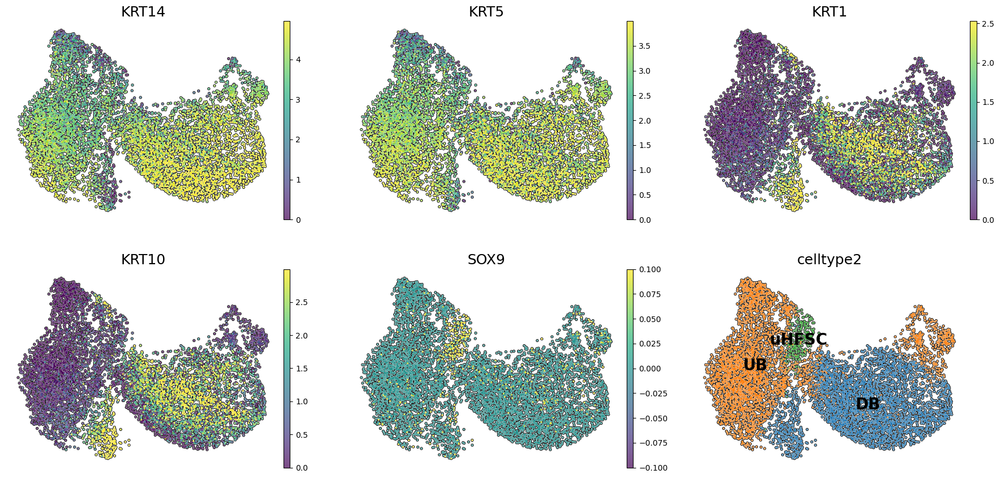

In [21]:
import matplotlib.pyplot as plt

axes = sc.pl.umap(
    adata,
    color=['KRT14', 'KRT5', 'KRT1', 'KRT10', 'SOX9', 'celltype2'],
    frameon=False,
    legend_loc='on data',
    legend_fontsize=20,
    s=20,
    add_outline=True,
    vmin=0,
    vmax='p90',
    ncols=3,
    return_fig=True  # importante para obtener los ejes
)

# Ajustar el tamaño de los títulos
for ax in axes.axes:  # axes.axes es la lista de subplots
    ax.set_title(ax.get_title(), fontsize=18)  # aquí cambias el tamaño

plt.show()

## Volcano plot

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 1
mean_cutoff = 0.02

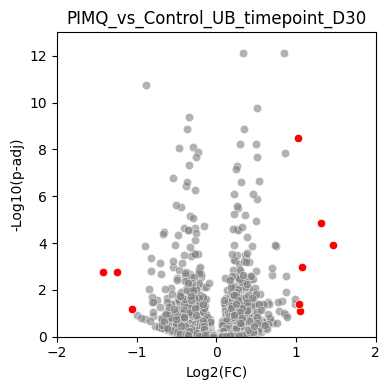

In [5]:
# Load data
file = 'diffxpy_PIMQ_vs_Control_UB_timepoint_D30.csv'

tmp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in tmp_df.columns:
    gene_column = 'Gene'
elif 'gene' in tmp_df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Extraer información del archivo
time = file.split('_timepoint_')[-1].split('.csv')[0]
basename = file.split('_timepoint')[0].split('Control_')[-1]

# Leer el archivo y realizar transformaciones
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-21)
tmp_df = tmp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
tmp_df['time'] = time
tmp_df['base'] = basename


# Convert gene names to uppercase for consistent comparison
tmp_df[gene_column] = tmp_df[gene_column].str.upper()

# Calculate -log10(qval)
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-22)
tmp_df = tmp_df[tmp_df['logqval'] < 15]
tmp_df = tmp_df[tmp_df['mean'] >= mean_cutoff]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=tmp_df, x='log2fc', y='logqval', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = tmp_df[
    (tmp_df['mean'] > mean_cutoff) & 
    (tmp_df['qval'] < qval_cutoff) & 
    (np.abs(tmp_df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='log2fc', y='logqval', color='red', label='P-adj < 0.1, L2FC > 0.5')


# Add labels for blue genes

# Configure plot settings
plt.xlabel('Log2(FC)')
plt.ylabel('-Log10(p-adj)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.xlim(-2, 2)
plt.ylim(0, 13)

#plt.legend()
plt.gca().get_legend().remove()  # Elimina la leyenda

plt.tight_layout()
# Configuración para guardar la image

#plt.savefig('../pdf_plots/D30_UB_volcano_plot.jpg', dpi=300, format='jpg', bbox_inches='tight')

# Mostrar la gráfica
plt.show()

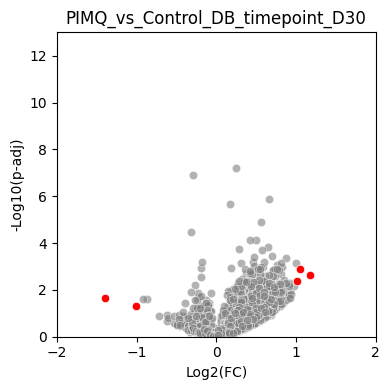

In [8]:
# Load data
file = 'diffxpy_PIMQ_vs_Control_DB_timepoint_D30.csv'

tmp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in tmp_df.columns:
    gene_column = 'Gene'
elif 'gene' in tmp_df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Extraer información del archivo
time = file.split('_timepoint_')[-1].split('.csv')[0]
basename = file.split('_timepoint')[0].split('Control_')[-1]

# Leer el archivo y realizar transformaciones
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-21)
tmp_df = tmp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
tmp_df['time'] = time
tmp_df['base'] = basename


# Convert gene names to uppercase for consistent comparison
tmp_df[gene_column] = tmp_df[gene_column].str.upper()

# Calculate -log10(qval)
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-22)
tmp_df = tmp_df[tmp_df['logqval'] < 15]
tmp_df = tmp_df[tmp_df['mean'] >= mean_cutoff]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=tmp_df, x='log2fc', y='logqval', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = tmp_df[
    (tmp_df['mean'] > mean_cutoff) & 
    (tmp_df['qval'] < qval_cutoff) & 
    (np.abs(tmp_df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='log2fc', y='logqval', color='red', label='P-adj < 0.1, L2FC > 0.5')


# Add labels for blue genes

# Configure plot settings
plt.xlabel('Log2(FC)')
plt.ylabel('-Log10(p-adj)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.xlim(-2, 2)
plt.ylim(0, 13)

#plt.legend()
plt.gca().get_legend().remove()  # Elimina la leyenda

plt.tight_layout()
# Configuración para guardar la image

#plt.savefig('../pdf_plots/D30_DB_volcano_plot.jpg', dpi=300, format='jpg', bbox_inches='tight')

# Mostrar la gráfica
plt.show()

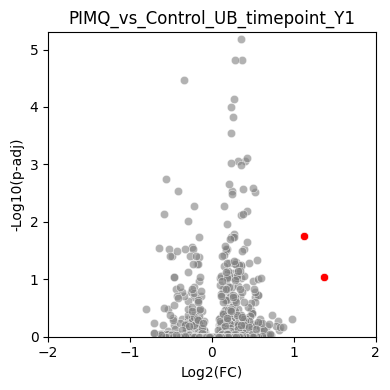

In [13]:
# Load data
file = 'diffxpy_PIMQ_vs_Control_UB_timepoint_Y1.csv'

tmp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in tmp_df.columns:
    gene_column = 'Gene'
elif 'gene' in tmp_df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Extraer información del archivo
time = file.split('_timepoint_')[-1].split('.csv')[0]
basename = file.split('_timepoint')[0].split('Control_')[-1]

# Leer el archivo y realizar transformaciones
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-21)
tmp_df = tmp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
tmp_df['time'] = time
tmp_df['base'] = basename


# Convert gene names to uppercase for consistent comparison
tmp_df[gene_column] = tmp_df[gene_column].str.upper()

# Calculate -log10(qval)
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-22)
tmp_df = tmp_df[tmp_df['logqval'] < 15]
tmp_df = tmp_df[tmp_df['mean'] >= mean_cutoff]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=tmp_df, x='log2fc', y='logqval', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = tmp_df[
    (tmp_df['mean'] > mean_cutoff) & 
    (tmp_df['qval'] < qval_cutoff) & 
    (np.abs(tmp_df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='log2fc', y='logqval', color='red', label='P-adj < 0.1, L2FC > 0.5')


# Add labels for blue genes

# Configure plot settings
plt.xlabel('Log2(FC)')
plt.ylabel('-Log10(p-adj)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.xlim(-2, 2)
plt.ylim(0, 5.3)

#plt.legend()
plt.gca().get_legend().remove()  # Elimina la leyenda

plt.tight_layout()
# Configuración para guardar la image

#plt.savefig('../pdf_plots/Y1_UB_volcano_plot.jpg', dpi=300, format='jpg', bbox_inches='tight')

# Mostrar la gráfica
plt.show()

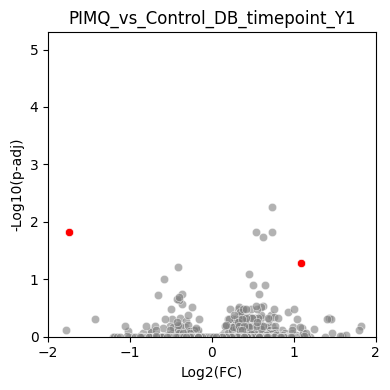

In [14]:
# Load data
file = 'diffxpy_PIMQ_vs_Control_DB_timepoint_Y1.csv'

tmp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in tmp_df.columns:
    gene_column = 'Gene'
elif 'gene' in tmp_df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Extraer información del archivo
time = file.split('_timepoint_')[-1].split('.csv')[0]
basename = file.split('_timepoint')[0].split('Control_')[-1]

# Leer el archivo y realizar transformaciones
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-21)
tmp_df = tmp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
tmp_df['time'] = time
tmp_df['base'] = basename


# Convert gene names to uppercase for consistent comparison
tmp_df[gene_column] = tmp_df[gene_column].str.upper()

# Calculate -log10(qval)
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-22)
tmp_df = tmp_df[tmp_df['logqval'] < 15]
tmp_df = tmp_df[tmp_df['mean'] >= mean_cutoff]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=tmp_df, x='log2fc', y='logqval', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = tmp_df[
    (tmp_df['mean'] > mean_cutoff) & 
    (tmp_df['qval'] < qval_cutoff) & 
    (np.abs(tmp_df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='log2fc', y='logqval', color='red', label='P-adj < 0.1, L2FC > 0.5')


# Add labels for blue genes

# Configure plot settings
plt.xlabel('Log2(FC)')
plt.ylabel('-Log10(p-adj)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.xlim(-2, 2)
plt.ylim(0, 5.3)

#plt.legend()
plt.gca().get_legend().remove()  # Elimina la leyenda

plt.tight_layout()
# Configuración para guardar la image

#plt.savefig('../pdf_plots/Y1_DB_volcano_plot.jpg', dpi=300, format='jpg', bbox_inches='tight')

# Mostrar la gráfica
plt.show()

In [13]:
day6 = pd.read_csv('/mnt/c/Users/sotougl/Projects/Data/downstream_outputs/PC_others_10_RM_filtering_subsetting_samples/D6_IMQ_vs_D6_Ctrl.csv')

day6_up = day6[(day6['padj'] < 0.05) & (day6['log2FoldChange'] > 0)]
day6_up = list(day6_up['symbol'])
day6_up = [s.upper() for s in day6_up]

day6_down = day6[(day6['padj'] < 0.05) & (day6['log2FoldChange'] < 0)]
day6_down = list(day6_down['symbol'])
day6_down = [s.upper() for s in day6_down]


In [14]:
big_df = pd.DataFrame()

celltype = 'UB'

files = ['diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_D30.csv',
        'diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_Y1.csv']

for file in files:
    print(file)
    
    # Extraer información del archivo
    time = file.split('_timepoint_')[-1].split('.csv')[0]
    basename = file.split('_timepoint')[0].split('Control_')[-1]
    
    # Leer el archivo y realizar transformaciones
    temp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)
    temp_df['logqval'] = -np.log10(temp_df['qval'] + 1e-21)
    temp_df = temp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
    temp_df['time'] = time
    temp_df['base'] = basename
    
    # Concatenar el DataFrame actual al acumulado
    big_df = pd.concat([big_df, temp_df], ignore_index=True)

qval_cutoff = 0.1
l2fc_cutoff = 0.5
mean_cutoff = 0.01


tmp_df = big_df[big_df['time'] == 'D30']
day30_UB_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] > l2fc_cutoff)]['gene'])
day30_UB_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] < -l2fc_cutoff)]['gene'])


tmp_df = big_df[big_df['time'] == 'Y1']
year1_UB_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] > l2fc_cutoff)]['gene'])
year1_UB_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] < -l2fc_cutoff)]['gene'])



big_df = pd.DataFrame()

celltype = 'DB'

files = ['diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_D30.csv',
        'diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_Y1.csv']

for file in files:
    print(file)
    
    # Extraer información del archivo
    time = file.split('_timepoint_')[-1].split('.csv')[0]
    basename = file.split('_timepoint')[0].split('Control_')[-1]
    
    # Leer el archivo y realizar transformaciones
    temp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)
    temp_df['logqval'] = -np.log10(temp_df['qval'] + 1e-21)
    temp_df = temp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
    temp_df['time'] = time
    temp_df['base'] = basename
    
    # Concatenar el DataFrame actual al acumulado
    big_df = pd.concat([big_df, temp_df], ignore_index=True)

qval_cutoff = 0.1
l2fc_cutoff = 0.5
mean_cutoff = 0.01


tmp_df = big_df[big_df['time'] == 'D30']
day30_DB_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] > l2fc_cutoff)]['gene'])
day30_DB_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] < -l2fc_cutoff)]['gene'])


tmp_df = big_df[big_df['time'] == 'Y1']
year1_DB_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] > l2fc_cutoff)]['gene'])
year1_DB_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] < -l2fc_cutoff)]['gene'])




diffxpy_PIMQ_vs_Control_UB_timepoint_D30.csv
diffxpy_PIMQ_vs_Control_UB_timepoint_Y1.csv
diffxpy_PIMQ_vs_Control_DB_timepoint_D30.csv
diffxpy_PIMQ_vs_Control_DB_timepoint_Y1.csv


In [20]:
print(len(day6_up), len(day6_down), len(day30_UB_up), len(day30_UB_down), len(day30_DB_up), len(day30_DB_down))

2555 2415 41 39 510 5


In [17]:
# Listas de genes (ejemplo, reemplázalas con tus datos)
day6_up = set(day6_up)  # Lista de genes upregulated at day 6 peak
day6_down = set(day6_down)  # Lista de genes downregulated at day 6 peak

day30_UB_up = set(day30_UB_up)  # Lista de genes upregulated at day 30 for UB
day30_UB_down = set(day30_UB_down)  # Lista de genes downregulated at day 30 for UB
day30_DB_up = set(day30_DB_up)  # Lista de genes upregulated at day 30 for DB
day30_DB_down = set(day30_DB_down)  # Lista de genes downregulated at day 30 for DB

year1_UB_up = set(year1_UB_up)  # Lista de genes upregulated at year 1 for UB
year1_UB_down = set(year1_UB_down)  # Lista de genes downregulated at year 1 for UB
year1_DB_up = set(year1_DB_up)  # Lista de genes upregulated at year 1 for DB
year1_DB_down = set(year1_DB_down)  # Lista de genes downregulated at year 1 for DB

# Intersección entre Day 6 y Day 30
intersections_day30 = {
    'day6_up_to_day30_UB_up': day6_up & day30_UB_up,
    'day6_up_to_day30_UB_down': day6_up & day30_UB_down,
    'day6_up_to_day30_DB_up': day6_up & day30_DB_up,
    'day6_up_to_day30_DB_down': day6_up & day30_DB_down,
    'day6_down_to_day30_UB_up': day6_down & day30_UB_up,
    'day6_down_to_day30_UB_down': day6_down & day30_UB_down,
    'day6_down_to_day30_DB_up': day6_down & day30_DB_up,
    'day6_down_to_day30_DB_down': day6_down & day30_DB_down
}

# Imprimir resultados de Day 6 a Day 30
print("Intersections from Day 6 to Day 30:")
for key, genes in intersections_day30.items():
    print(f"{key}: {len(genes)} genes")
    print(f"Genes: {genes}")

# Intersecciones con Year 1 para cada combinación de Day 30
intersections_year1 = {}
for key, genes in intersections_day30.items():
    if 'UB' in key:
        intersections_year1[key] = {
            'year1_up': genes & year1_UB_up,
            'year1_down': genes & year1_UB_down
        }
    elif 'DB' in key:
        intersections_year1[key] = {
            'year1_up': genes & year1_DB_up,
            'year1_down': genes & year1_DB_down
        }

# Imprimir resultados de las intersecciones con Year 1
print("\nIntersections with Year 1:")
for key, data in intersections_year1.items():
    for year_key, genes in data.items():
        print(f"{key} -> {year_key}: {len(genes)} genes")
        print(f"Genes: {genes}")

Intersections from Day 6 to Day 30:
day6_up_to_day30_UB_up: 10 genes
Genes: {'EHF', 'CASP1', 'RUNX1', 'PHYH', 'CASP4', 'GDA', 'AIM2', 'STEAP4', 'POSTN', 'SAMD5'}
day6_up_to_day30_UB_down: 26 genes
Genes: {'SRXN1', 'FDPS', 'NDUFA4', 'GCLM', 'GCAT', 'CBR3', 'NQO1', 'NHP2', 'FABP5', 'AQP3', 'MGST1', 'TSPAN3', 'GCSH', 'SRM', 'CSTDC5', 'TXN1', 'BEX3', 'PPA1', 'KRT17', 'MRTO4', 'TIMM8A1', 'TIPIN', 'SBSN', 'KRT6A', 'EBP', 'CST6'}
day6_up_to_day30_DB_up: 37 genes
Genes: {'CLCN5', 'KTI12', 'SLC39A6', 'TCOF1', 'STARD5', 'UBE2J1', 'IDE', 'TANK', 'LRRC1', 'PARP8', 'LGALS9', 'INTS7', 'EYA3', 'TFRC', 'NOD2', 'CERS3', 'TMEM50B', 'HMGCR', 'CLYBL', 'SKIL', 'LRRFIP1', 'HR', 'LSG1', 'STRN', 'DAG1', 'TMEM41B', 'WBP11', 'AGFG1', 'COX10', 'SHB', 'CARMIL1', 'NUP93', 'CASP14', 'SLC25A13', 'KDM5C', 'GPR160', 'BAZ1A'}
day6_up_to_day30_DB_down: 3 genes
Genes: {'SPRR1B', 'GPX2', 'MAD2L1'}
day6_down_to_day30_UB_up: 20 genes
Genes: {'FHOD3', 'IL12RB2', 'SEMA3D', 'THSD4', 'STAT2', 'CLCA3A2', 'FGD6', 'TMPRSS11F', 'VS

In [64]:
list(day6.symbol)

['Gnai3',
 'Cdc45',
 'Scml2',
 'Narf',
 'Cav2',
 'Klf6',
 'Scmh1',
 'Cox5a',
 'Tbx2',
 'Ngfr',
 'Wnt3',
 'Wnt9a',
 'Fer',
 'Xpo6',
 'Tfe3',
 'Axin2',
 'Brat1',
 'Gna12',
 'Slc22a18',
 'Pih1d2',
 'Dlat',
 'Sdhd',
 'Ccnd2',
 'Gpr107',
 'Slfn4',
 'Scnn1g',
 'Drp2',
 'Tspan32',
 'Lhx2',
 'Clec2g',
 'Gmpr',
 'Mid2',
 'Trim25',
 'Dgke',
 'Scpep1',
 'Mnt',
 'Itgb2',
 'Hddc2',
 'Tpd52l1',
 'Pemt',
 'Cdh1',
 'Cdh4',
 'Ckmt1',
 'Bcl6b',
 'Clec10a',
 'Alox12',
 'Comt',
 'Rtca',
 'Dbt',
 'Dazap2',
 'Mcts1',
 'Rnf17',
 'Trappc10',
 'Ccm2',
 'Tbrg4',
 'Tmprss2',
 'Mx1',
 'Fap',
 'Ndufa9',
 'Egfl6',
 'Lck',
 'Cttnbp2',
 'Galnt1',
 'Mkrn2',
 'Pparg',
 'Raf1',
 'Septin1',
 'Pdgfb',
 'Acvrl1',
 'Tamalin',
 'Acvr1b',
 'Tom1l2',
 'Zfp385a',
 'Itga5',
 'Wdr77',
 'Atp5pb',
 'Sox9',
 'Hnrnpd',
 'Dynlt1c',
 'C1d',
 'Gm2a',
 'Krit1',
 'Clcn4',
 'Hk2',
 'Myo18a',
 'Cd52',
 'Abhd15',
 'Hoxb6',
 'Loxl3',
 'Kat2b',
 'Rab5b',
 'Dnmt3l',
 'Aire',
 'Icosl',
 'Spg7',
 'Sult5a1',
 'Rpl13',
 'Chmp1a',
 'Rpa1',
 'Serpinf

In [117]:
day6 = pd.read_csv('/mnt/c/Users/sotougl/Projects/Data/downstream_outputs/PC_others_10_RM_filtering_subsetting_samples/D6_IMQ_vs_D6_Ctrl.csv')
day6 = day6[day6['ensembl'] != 'ENSMUSG00000116378']
day6.loc[(day6['padj'] >= 0.05) | (np.abs(day6['log2FoldChange']) == 0), 'log2FoldChange'] = 0
day6.index = [i.upper() for i in list(day6.symbol)]
day6 = day6[['log2FoldChange']]
day6.index.name = 'symbol'


In [160]:
big_df = pd.DataFrame()

celltype = 'UB'

files = ['diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_D30.csv',
        'diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_Y1.csv']

for file in files:
    print(file)
    
    # Extraer información del archivo
    time = file.split('_timepoint_')[-1].split('.csv')[0]
    basename = file.split('_timepoint')[0].split('Control_')[-1]
    
    # Leer el archivo y realizar transformaciones
    temp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)
    temp_df['logqval'] = -np.log10(temp_df['qval'] + 1e-21)
    temp_df = temp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
    temp_df['time'] = time
    temp_df['base'] = basename
    
    # Concatenar el DataFrame actual al acumulado
    big_df = pd.concat([big_df, temp_df], ignore_index=True)

qval_cutoff = 0.1
l2fc_cutoff = 0.5
mean_cutoff = 0.01


day30 = big_df[big_df['time'] == 'D30']
day30.index = day30.gene
day30.loc[(day30['qval'] > 0.1) | (day30['mean'] <= mean_cutoff) | (np.abs(day30['log2fc']) <= l2fc_cutoff), 'log2fc'] = 0
day30 = day30[['log2fc']]
day30.index.name = 'symbol'

year1 = big_df[big_df['time'] == 'Y1']
year1.index = year1.gene
#year1.loc[(year1['qval'] > 0.1) | (year1['mean'] <= mean_cutoff) | (np.abs(year1['log2fc']) <= l2fc_cutoff), 'log2fc'] = 0
year1 = year1[['log2fc']]
year1.index.name = 'symbol'

merged_df = day6.merge(day30, how='outer', on='symbol', suffixes=('_day6', '_day30')).merge(
    year1, how='outer', on='symbol'
)
merged_df.rename(columns={'log2FoldChange': 'L2FC_D6',
                         'log2fc_x' : 'L2FC_D30',
                         'log2fc_y' : 'L2FC_Y1'}, inplace=True)
merged_df

diffxpy_PIMQ_vs_Control_UB_timepoint_D30.csv
diffxpy_PIMQ_vs_Control_UB_timepoint_Y1.csv


,L2FC_D6,L2FC_D30,L2FC_Y1
symbol,,,
GNAI3,0.000000,0.0,0.084695
CDC45,0.929230,0.0,0.425584
SCML2,-1.949601,0.0,-0.219751
NARF,0.000000,0.0,0.109631
CAV2,0.000000,0.0,0.050473
...,...,...,...
GM16046,NaN,NaN,-0.157331
GM16090,NaN,NaN,-0.508658
GM15345,NaN,NaN,-0.347440


In [161]:
# 10 genes
d6_up_d30_ub_up = ['EHF', 'CASP1', 'RUNX1', 'PHYH', 'CASP4', 'GDA', 'AIM2', 'STEAP4', 'POSTN', 'SAMD5']

# 26 genes
d6_up_d30_ub_down = ['SRXN1', 'FDPS', 'NDUFA4', 'GCLM', 'GCAT', 'CBR3', 'NQO1', 'NHP2', 'FABP5', 'AQP3', 'MGST1', 'TSPAN3', 'GCSH', 'SRM', 'CSTDC5', 'TXN1', 'BEX3', 'PPA1', 'KRT17', 'MRTO4', 'TIMM8A1', 'TIPIN', 'SBSN', 'KRT6A', 'EBP', 'CST6']

# 20 genes
d6_down_d30_ub_up = ['FHOD3', 'IL12RB2', 'SEMA3D', 'THSD4', 'STAT2', 'CLCA3A2', 'FGD6', 'TMPRSS11F', 'VSIR', 'NUAK1', 'PARP14', 'CLCA3A1', 'SLC4A8', 'KCNJ2', 'SECTM1A', 'IFIH1', 'WNT5A', 'CACNB3', 'CSGALNACT1', 'SORL1']

# 4 genes
d6_down_d30_ub_down = ['RAB15', 'MT4', 'GPC3', 'HPGDS']

# 37 genes
d6_up_d30_db_up = ['CLCN5', 'KTI12', 'SLC39A6', 'TCOF1', 'STARD5', 'UBE2J1', 'IDE', 'TANK', 'LRRC1', 'PARP8', 'LGALS9', 'INTS7', 'EYA3', 'TFRC', 'NOD2', 'CERS3', 'TMEM50B', 'HMGCR', 'CLYBL', 'SKIL', 'LRRFIP1', 'HR', 'LSG1', 'STRN', 'DAG1', 'TMEM41B', 'WBP11', 'AGFG1', 'COX10', 'SHB', 'CARMIL1', 'NUP93', 'CASP14', 'SLC25A13', 'KDM5C', 'GPR160', 'BAZ1A']

# 3 genes
d6_up_d30_db_down = ['SPRR1B', 'GPX2', 'MAD2L1']

# 112 genes
d6_down_d30_db_up = ['AGO4', 'MAN1C1', 'RAB30', 'GRAMD1B', 'PLAGL1', 'RNF13', 'ADARB1', 'FYCO1', 'CLCA2', 'FGD4', 'MYSM1', 'TMEM106C', 'DNM3', 'CALCRL', 'TNRC18', 'ZFP667', 'PRKAG2', 'SLC16A9', 'EPC1', 'ACSBG1', 'FNDC3B', 'EXTL1', 'AKAP9', 'ARHGAP42', 'MTM1', 'ABCC5', 'RGMB', 'WDFY3', 'EHBP1', 'TWSG1', 'GK5', 'MTMR3', 'RABGAP1', 'UVRAG', 'CDK19', 'MLXIP', 'ITGA2', 'L3MBTL3', 'AGFG2', 'TBC1D8', 'SORBS1', 'ZFP609', 'RASA1', 'MICALL1', 'CREBRF', 'MARVELD3', 'RMND5A', 'DAB2IP', 'DNAJC13', 'HIVEP1', 'ZC3H6', 'FLVCR1', 'RAPGEF2', 'CYP3A13', 'CDKL2', 'TRIM2', 'ZYG11B', 'MAFK', 'VEZF1', 'MAP3K4', 'ZFP398', 'ABHD2', 'CHD3', 'ZMYND11', 'KLHL24', 'RICTOR', 'NUAK1', 'DDX17', 'LIMCH1', 'MSI2', 'AHDC1', 'KLHL5', 'CRIM1', 'CYP39A1', 'PCMTD1', 'HOOK2', '2900026A02RIK', 'NIN', 'NAV2', 'PLEKHN1', 'CCDC88C', 'PLSCR4', 'LIFR', 'RSBN1L', 'LRCH1', 'GPBP1L1', 'AKAP7', 'RIPK2', 'TRAPPC10', 'ADD1', 'SVIL', 'TTC28', 'CERK', 'PHF20', 'FLOT1', 'TPK1', 'EPS8L2', 'TNRC6C', 'PIK3C2G', 'ABCC4', 'HLF', 'SPECC1L', 'SIPA1L3', 'GAMT', 'P2RY1', 'RELB', 'AR', 'NFYA', 'TMEM131L', 'EXPH5', 'INSR', 'FBXL20']

# 1 genes
d6_up_d30_ub_up_yr1_ub_up= ['AIM2']

# 1 genes
d6_up_d30_ub_up_yr1_ub_down = ['POSTN']



<Axes: ylabel='symbol'>

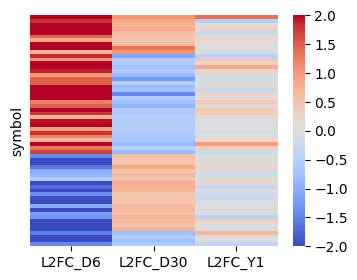

In [162]:
gr1 = d6_up_d30_ub_up_yr1_ub_up
gr2 = d6_up_d30_ub_up_yr1_ub_down
gr3 = list(set(d6_up_d30_ub_up).difference(set(gr1 + gr2)))
gr4 = list(set(d6_up_d30_ub_down).difference(set(gr1 + gr2 + gr3)))
gr5 = list(set(d6_down_d30_ub_up).difference(set(gr1 + gr2 + gr3 + gr4)))
gr6 = list(set(d6_down_d30_ub_down).difference(set(gr1 + gr2 + gr3 + gr4 + gr5)))

gr7 = list(set(list(merged_df[merged_df['L2FC_D6'] > 0].index)).difference(set(gr1+gr2+gr3+gr4+gr5+gr6 )))
gr8 = list(set(list(merged_df[merged_df['L2FC_D6'] < 0].index)).difference(set(gr1+gr2+gr3+gr4+gr5+gr6 )))

plt.figure(figsize=(4, 3))  

sns.heatmap(merged_df.loc[gr1 + gr2 + gr3 + gr4 + gr5 + gr6 ], vmax = 2, vmin = -2, cmap = 'coolwarm', yticklabels=False)

#plt.savefig("../pdf_plots/Heatmap_scRNA_UB_resolution.pdf", format="pdf", dpi = 300, bbox_inches="tight")


In [163]:
big_df = pd.DataFrame()

celltype = 'DB'

files = ['diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_D30.csv',
        'diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_Y1.csv']

for file in files:
    print(file)
    
    # Extraer información del archivo
    time = file.split('_timepoint_')[-1].split('.csv')[0]
    basename = file.split('_timepoint')[0].split('Control_')[-1]
    
    # Leer el archivo y realizar transformaciones
    temp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)
    temp_df['logqval'] = -np.log10(temp_df['qval'] + 1e-21)
    temp_df = temp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
    temp_df['time'] = time
    temp_df['base'] = basename
    
    # Concatenar el DataFrame actual al acumulado
    big_df = pd.concat([big_df, temp_df], ignore_index=True)

qval_cutoff = 0.1
l2fc_cutoff = 0.5
mean_cutoff = 0.01


day30 = big_df[big_df['time'] == 'D30']
day30.index = day30.gene
day30.loc[(day30['qval'] > 0.1) | (day30['mean'] <= mean_cutoff) | (np.abs(day30['log2fc']) <= l2fc_cutoff), 'log2fc'] = 0
day30 = day30[['log2fc']]
day30.index.name = 'symbol'

year1 = big_df[big_df['time'] == 'Y1']
year1.index = year1.gene
#year1.loc[(year1['qval'] > 0.1) | (year1['mean'] <= mean_cutoff) | (np.abs(year1['log2fc']) <= l2fc_cutoff), 'log2fc'] = 0
year1 = year1[['log2fc']]
year1.index.name = 'symbol'

merged_df = day6.merge(day30, how='outer', on='symbol', suffixes=('_day6', '_day30')).merge(
    year1, how='outer', on='symbol'
)
merged_df.rename(columns={'log2FoldChange': 'L2FC_D6',
                         'log2fc_x' : 'L2FC_D30',
                         'log2fc_y' : 'L2FC_Y1'}, inplace=True)
merged_df

diffxpy_PIMQ_vs_Control_DB_timepoint_D30.csv
diffxpy_PIMQ_vs_Control_DB_timepoint_Y1.csv


,L2FC_D6,L2FC_D30,L2FC_Y1
symbol,,,
GNAI3,0.000000,0.0,-0.109917
CDC45,0.929230,0.0,-0.535532
SCML2,-1.949601,0.0,NaN
NARF,0.000000,0.0,-0.086412
CAV2,0.000000,0.0,-0.125007
...,...,...,...
TMLHE,NaN,0.0,0.054721
CAAA01147332.1,NaN,0.0,0.449866
AC149090.1,NaN,0.0,-0.311699


<Axes: ylabel='symbol'>

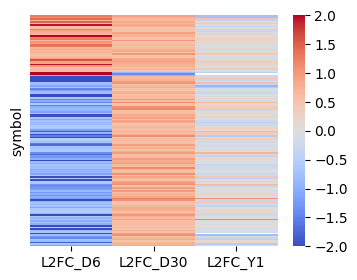

In [164]:
plt.figure(figsize=(4, 3))  

sns.heatmap(merged_df.loc[d6_up_d30_db_up + d6_up_d30_db_down + d6_down_d30_db_up ], vmax = 2, vmin = -2, cmap = 'coolwarm', yticklabels=False)
#plt.savefig("../pdf_plots/Heatmap_scRNA_DB_resolution.pdf", format="pdf", dpi = 300, bbox_inches="tight")


In [144]:
big_df = pd.DataFrame()

celltype = 'uHFSC'

files = ['diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_D30.csv',
        'diffxpy_PIMQ_vs_Control_' + celltype + '_timepoint_Y1.csv']

for file in files:
    print(file)
    
    # Extraer información del archivo
    time = file.split('_timepoint_')[-1].split('.csv')[0]
    basename = file.split('_timepoint')[0].split('Control_')[-1]
    
    # Leer el archivo y realizar transformaciones
    temp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)
    temp_df['logqval'] = -np.log10(temp_df['qval'] + 1e-21)
    temp_df = temp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
    temp_df['time'] = time
    temp_df['base'] = basename
    
    # Concatenar el DataFrame actual al acumulado
    big_df = pd.concat([big_df, temp_df], ignore_index=True)

qval_cutoff = 0.1
l2fc_cutoff = 0.5
mean_cutoff = 0.01


day30 = big_df[big_df['time'] == 'D30']
day30.index = day30.gene
day30.loc[(day30['qval'] > 0.1) | (day30['mean'] <= mean_cutoff) | (np.abs(day30['log2fc']) <= l2fc_cutoff), 'log2fc'] = 0
day30 = day30[['log2fc']]
day30.index.name = 'symbol'

year1 = big_df[big_df['time'] == 'Y1']
year1.index = year1.gene
year1.loc[(year1['qval'] > 0.1) | (year1['mean'] <= mean_cutoff) | (np.abs(year1['log2fc']) <= l2fc_cutoff), 'log2fc'] = 0
year1 = year1[['log2fc']]
year1.index.name = 'symbol'

merged_df = day6.merge(day30, how='outer', on='symbol', suffixes=('_day6', '_day30')).merge(
    year1, how='outer', on='symbol'
)
merged_df.rename(columns={'log2FoldChange': 'L2FC_D6',
                         'log2fc_x' : 'L2FC_D30',
                         'log2fc_y' : 'L2FC_Y1'}, inplace=True)
merged_df

diffxpy_PIMQ_vs_Control_uHFSC_timepoint_D30.csv
diffxpy_PIMQ_vs_Control_uHFSC_timepoint_Y1.csv


,L2FC_D6,L2FC_D30,L2FC_Y1
symbol,,,
GNAI3,0.000000,0.0,0.0
CDC45,0.929230,NaN,NaN
SCML2,-1.949601,0.0,NaN
NARF,0.000000,0.0,0.0
CAV2,0.000000,0.0,0.0
...,...,...,...
GM47283,NaN,0.0,0.0
CAAA01118383.1,NaN,0.0,0.0
VAMP7,NaN,0.0,NaN


In [149]:
merged_df[(merged_df['L2FC_D30'] != 0) & (merged_df['L2FC_D30'].notna()) ]
#merged_df[(merged_df['L2FC_Y1'] != 0) & (merged_df['L2FC_Y1'].notna()) ]

,L2FC_D6,L2FC_D30,L2FC_Y1
symbol,,,
EVC,-1.523553,283.913085,NaN
MT2,-0.643940,-0.840589,0.0
ZMYND15,1.305141,283.913085,NaN
SORT1,1.208777,283.913085,NaN


In [33]:
upper_genes = ['AGO4', 'MAN1C1', 'RAB30', 'GRAMD1B', 'PLAGL1', 'RNF13', 'ADARB1', 'FYCO1', 'CLCA2', 'FGD4', 'MYSM1', 'TMEM106C', 'DNM3', 'CALCRL', 'TNRC18', 'ZFP667', 'PRKAG2', 'SLC16A9', 'EPC1', 'ACSBG1', 'FNDC3B', 'EXTL1', 'AKAP9', 'ARHGAP42', 'MTM1', 'ABCC5', 'RGMB', 'WDFY3', 'EHBP1', 'TWSG1', 'GK5', 'MTMR3', 'RABGAP1', 'UVRAG', 'CDK19', 'MLXIP', 'ITGA2', 'L3MBTL3', 'AGFG2', 'TBC1D8', 'SORBS1', 'ZFP609', 'RASA1', 'MICALL1', 'CREBRF', 'MARVELD3', 'RMND5A', 'DAB2IP', 'DNAJC13', 'HIVEP1', 'ZC3H6', 'FLVCR1', 'RAPGEF2', 'CYP3A13', 'CDKL2', 'TRIM2', 'ZYG11B', 'MAFK', 'VEZF1', 'MAP3K4', 'ZFP398', 'ABHD2', 'CHD3', 'ZMYND11', 'KLHL24', 'RICTOR', 'NUAK1', 'DDX17', 'LIMCH1', 'MSI2', 'AHDC1', 'KLHL5', 'CRIM1', 'CYP39A1', 'PCMTD1', 'HOOK2', '2900026A02RIK', 'NIN', 'NAV2', 'PLEKHN1', 'CCDC88C', 'PLSCR4', 'LIFR', 'RSBN1L', 'LRCH1', 'GPBP1L1', 'AKAP7', 'RIPK2', 'TRAPPC10', 'ADD1', 'SVIL', 'TTC28', 'CERK', 'PHF20', 'FLOT1', 'TPK1', 'EPS8L2', 'TNRC6C', 'PIK3C2G', 'ABCC4', 'HLF', 'SPECC1L', 'SIPA1L3', 'GAMT', 'P2RY1', 'RELB', 'AR', 'NFYA', 'TMEM131L', 'EXPH5', 'INSR', 'FBXL20']

In [56]:
enr = gseapy.enrichr(
    gene_list = list(day6_down),
    gene_sets = ["GO_Biological_Process_2023"],  # Cambia a "GO_Cellular_Component_2021" o "GO_Molecular_Function_2021" según necesidad
    #background = list(day6_up) + list(day6_down),
    organism = 'Mouse',  # Cambia a 'Mouse' si trabajas con ratones
    outdir = None,  # Carpeta de salida para guardar los resultados
)

results = enr.results
#results
results[results['Adjusted P-value'] < 0.1]['Term'].values

array(['Positive Regulation Of GTPase Activity (GO:0043547)',
       'Activation Of GTPase Activity (GO:0090630)',
       'Regulation Of GTPase Activity (GO:0043087)',
       'Negative Regulation Of Neuron Apoptotic Process (GO:0043524)',
       'Regulation Of Axonogenesis (GO:0050770)',
       'Regulation Of Hydrolase Activity (GO:0051336)',
       'Negative Regulation Of Neuron Death (GO:1901215)',
       'Response To Fibroblast Growth Factor (GO:0071774)',
       'Positive Regulation Of Protein Binding (GO:0032092)',
       'Regulation Of Neuron Projection Development (GO:0010975)',
       'Negative Regulation Of Wnt Signaling Pathway (GO:0030178)',
       'Regulation Of Small GTPase Mediated Signal Transduction (GO:0051056)',
       'Negative Regulation Of Cell Differentiation (GO:0045596)',
       'Negative Regulation Of MAP Kinase Activity (GO:0043407)',
       'Negative Regulation Of Cell Growth (GO:0030308)',
       'Positive Regulation Of DNA-templated Transcription (GO:004589

In [57]:
results[results['Term'] == 'Negative Regulation Of Cell Differentiation (GO:0045596)']

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
12,GO_Biological_Process_2023,Negative Regulation Of Cell Differentiation (G...,45/207,0.000058,0.018142,0,0,2.042077,19.916914,YAP1;NOTCH1;RORA;GATA3;LIMD1;DLL1;FOXO1;ZFP36L...


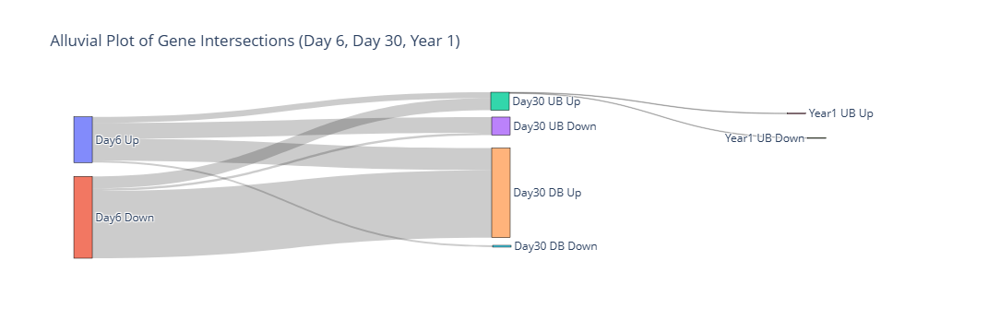

In [19]:
import plotly.graph_objects as go

# Procesar los datos de las intersecciones
# Usaremos las variables intersections_day30 y intersections_year1 del código previo

# Crear etiquetas (labels) para los nodos del Sankey
labels = [
    "Day6 Up", "Day6 Down",  # Day 6
    "Day30 UB Up", "Day30 UB Down", "Day30 DB Up", "Day30 DB Down",  # Day 30
    "Year1 UB Up", "Year1 UB Down", "Year1 DB Up", "Year1 DB Down"  # Year 1
]

# Mapear los labels a índices
label_indices = {label: idx for idx, label in enumerate(labels)}

# Inicializar listas para los nodos y conexiones
source = []
target = []
values = []

# Combinar las intersecciones de Day6 con Day30
for key, genes in intersections_day30.items():
    if "up_to_day30" in key:
        source_label = "Day6 Up"
    else:
        source_label = "Day6 Down"

    if "UB_up" in key:
        target_label = "Day30 UB Up"
    elif "UB_down" in key:
        target_label = "Day30 UB Down"
    elif "DB_up" in key:
        target_label = "Day30 DB Up"
    elif "DB_down" in key:
        target_label = "Day30 DB Down"
    else:
        continue

    # Registrar los enlaces para Day 6 a Day 30
    source.append(label_indices[source_label])
    target.append(label_indices[target_label])
    values.append(len(genes))

# Combinar las intersecciones de Day30 con Year1
for day30_key, year1_data in intersections_year1.items():
    if "UB" in day30_key:
        if "up" in day30_key:
            source_label = "Day30 UB Up"
        else:
            source_label = "Day30 UB Down"
    elif "DB" in day30_key:
        if "up" in day30_key:
            source_label = "Day30 DB Up"
        else:
            source_label = "Day30 DB Down"
    else:
        continue

    for year1_key, genes in year1_data.items():
        if "year1_up" in year1_key:
            target_label = "Year1 UB Up" if "UB" in day30_key else "Year1 DB Up"
        elif "year1_down" in year1_key:
            target_label = "Year1 UB Down" if "UB" in day30_key else "Year1 DB Down"
        else:
            continue

        # Registrar los enlaces para Day 30 a Year 1
        source.append(label_indices[source_label])
        target.append(label_indices[target_label])
        values.append(len(genes))

# Crear el Sankey diagram (alluvial plot)
fig = go.Figure(go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels
    ),
    link=dict(
        source=source,
        target=target,
        value=values
    )
))

# Personalizar el diseño
fig.update_layout(title_text="Alluvial Plot of Gene Intersections (Day 6, Day 30, Year 1)", font_size=12)

# Mostrar el gráfico
fig.show()



# Guardar el gráfico como PDF
fig.write_image("alluvial_plot.pdf", format="pdf")


In [158]:
len(day6_up) + len(day6_down)

4970

In [ ]:
len()

In [776]:
day6 = pd.read_csv('/mnt/c/Users/sotougl/Projects/Data/downstream_outputs/PC_others_10_RM_filtering_subsetting_samples/D6_IMQ_vs_D6_Ctrl.csv')
day6 = day6[(day6['padj'] < 0.05) & (day6['log2FoldChange'] > 0)]
day6 = list(day6['symbol'])
day6 = [s.upper() for s in day6]

In [777]:
[len(D30_up), len(D30_down), len(D30_ns), len(Y1_up), len(Y1_down), len(Y1_ns), len(aging_up), len(aging_down), len(aging_ns),
len(pimq_aging_up), len(pimq_aging_down), len(pimq_aging_ns)]

[41, 39, 9672, 5, 5, 9790, 210, 588, 7561, 109, 74, 9104]

In [780]:
D30_up

['AIM2',
 'PHYH',
 'IFIH1',
 'EHF',
 'POSTN',
 'CLCA3A1',
 'CLCA3A2',
 'GM49890',
 'STEAP4',
 'SEMA3D',
 'TMPRSS11F',
 'D730045B01RIK',
 '1700028E10RIK',
 'GPNMB',
 'IL12RB2',
 'CSGALNACT1',
 'CASP1',
 'CASP4',
 'SORL1',
 'THSD4',
 'SAMD5',
 'VSIR',
 'TSPEAR',
 'NUAK1',
 'NTN4',
 'FGD6',
 'STAT2',
 'KCNJ2',
 'SECTM1A',
 'SLC10A1',
 'ELMO1',
 'WNT5A',
 'GM29904',
 'CACNB3',
 'SLC4A8',
 'PARP14',
 'RUNX1',
 'FHOD3',
 'IIGP1',
 '1500015L24RIK',
 'GDA']

In [778]:
print(len(set(D30_up).intersection(Y1_up)))
print(len(set(D30_up + D30_down).intersection(Y1_up + Y1_down)))

1
2


In [779]:
print(len(set(D30_up).intersection(day6))/len(D30_up))
print(len(set(D30_down).intersection(day6))/len(D30_down))

print(len(set(Y1_up).intersection(day6))/len(Y1_up))
print(len(set(Y1_down).intersection(day6))/len(Y1_down))



0.24390243902439024
0.6666666666666666
0.4
0.4


In [721]:
big_df[big_df['gene'] == 'KRT79']

,gene,pval,qval,log2fc,mean,logqval,time,base
10906,KRT79,0.030,0.399,-0.851,0.015,0.399,D30,UB
23656,KRT79,0.624,0.999,-0.251,0.009,0.000,Y1,UB
36477,KRT79,0.069,0.270,0.751,0.016,0.569,diffxpy_control_D30_vs_Y1_UB,diffxpy_control_D30_vs_Y1_UB.csv
49522,KRT79,0.762,0.953,0.151,0.008,0.021,diffxpy_PIMQ_D30_vs_Y1_UB,diffxpy_PIMQ_D30_vs_Y1_UB.csv


In [ ]:
tmp_df = big_df[big_df['time'] == 'diffxpy_control_D30_vs_Y1_' + celltype]
aging_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] < -l2fc_cutoff)]['gene'])
aging_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] > l2fc_cutoff)]['gene'])
aging_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])

tmp_df = big_df[big_df['time'] == 'diffxpy_PIMQ_D30_vs_Y1_' + celltype]
pimq_aging_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] < -l2fc_cutoff)]['gene'])
pimq_aging_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] > mean_cutoff) & (tmp_df['log2fc'] > l2fc_cutoff)]['gene'])
pimq_aging_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])


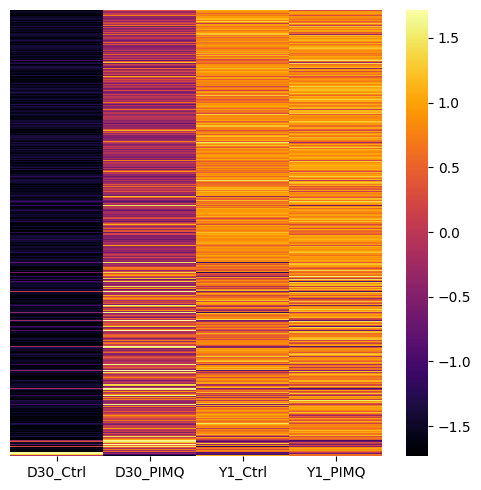

289 0 221 0 0 5


In [705]:
g1 = list(set(D30_up).intersection(aging_up))
g2 = list(set(D30_up).intersection(aging_down))
g3 = list(set(D30_up).difference(set(g1)).difference(set(g2)))
g4 = list(set(D30_down).intersection(aging_up))
g5 = list(set(D30_down).intersection(aging_down))
g6 = list(set(D30_down).difference(set(g4)).difference(set(g5)))

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# Combinar todos los genes en el orden deseado
all_genes = g1 + g2 + g3 + g4+ g5 + g6

# Filtrar el dataframe original con ese orden
subdf = df[all_genes]

# Normalización z-score por columna
df_z = subdf.apply(zscore, axis=0)

plt.figure(figsize=(5, 5))

ax = sns.heatmap(df_z.T,
                 cmap = "inferno",
                 annot = False,
                 cbar = True,
                 yticklabels = False, 
                 xticklabels = True)


plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(len(g1), len(g2), len(g3), len(g4), len(g5) , len(g6))

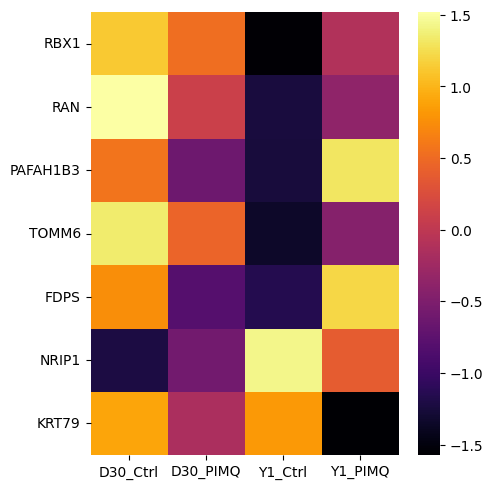

0 4 1 2 0 0


In [706]:
g1 = list(set(Y1_up).intersection(aging_up))
g2 = list(set(Y1_up).intersection(aging_down))
g3 = list(set(Y1_up).difference(set(g1)).difference(set(g2)))
g4 = list(set(Y1_down).intersection(aging_up))
g5 = list(set(Y1_down).intersection(aging_down))
g6 = list(set(Y1_down).difference(set(g4)).difference(set(g5)))

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# Combinar todos los genes en el orden deseado
all_genes = g1 + g2 + g3 + g4+ g5 + g6

# Filtrar el dataframe original con ese orden
subdf = df[all_genes]

# Normalización z-score por columna
df_z = subdf.apply(zscore, axis=0)

plt.figure(figsize=(5, 5))

ax = sns.heatmap(df_z.T,
                 cmap = "inferno",
                 annot = False,
                 cbar = True,
                 yticklabels = True, 
                 xticklabels = True)


plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(len(g1), len(g2), len(g3), len(g4), len(g5) , len(g6))

In [ ]:
# TPA signature is more present in what celltypes?
# Take TPA Signature gene,
# Do an average of these genes per cell
# Plot this per cell type, per condition, per timepoint

In [28]:
file = 'diffxpy_control_D30_vs_Y1_DB.csv'
print(file)
qval_cutoff = 0.1
mean_cutoff = 0.01
l2fc_cutoff = 0.25

# Extraer información del archivo
time = file.split('_timepoint_')[-1].split('.csv')[0]
basename = file.split('_timepoint')[0].split('Control_')[-1]

# Leer el archivo y realizar transformaciones
tmp_df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)
tmp_df['logqval'] = -np.log10(tmp_df['qval'] + 1e-21)
tmp_df = tmp_df[['gene', 'pval', 'qval', 'log2fc', 'mean', 'logqval']]
tmp_df['time'] = time
tmp_df['base'] = basename


#tmp_df = big_df[big_df['time'] == 'diffxpy_control_D30_vs_Y1_all_data']
aging_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
aging_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
aging_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])
back_genes = list(tmp_df[tmp_df['mean'] >= 0.01]['gene'])

diffxpy_control_D30_vs_Y1_DB.csv


In [29]:
from gseapy import Msigdb

In [30]:
lt_genes = pd.read_excel('/mnt/c/Users/sotougl/Downloads/LT_annotations_wTPAnote.xlsx')
list(lt_genes['SYMBOL'].values)

['Snx10',
 'Sema4f',
 'Clec2g',
 'Atf7ip',
 'Sox5',
 'Bcat1',
 'Bcat1',
 'Frmd6',
 'Syt16',
 'Rps6ka5',
 'Cdc42bpb',
 'Ptprn2',
 'Clmp',
 'Clmp',
 'Cadm1',
 'Il18',
 'Il18',
 'Zfp280d',
 'Mapk6',
 'Lrrc1',
 'Tpbg',
 'Ccnl1',
 'Gm1647',
 'Cd2',
 'Vav3',
 'Mettl14',
 'Prss12',
 'Prss12',
 'Adgrl2',
 'Gipc2',
 'Alg2',
 'Klf4',
 'Susd1',
 'Glis1',
 'Calr4',
 'Fhl3',
 'Rnase2b',
 '2900040C04Rik',
 '4930431P22Rik',
 'Dgkh',
 'Vwa8',
 'Nr3c1',
 '1500015A07Rik',
 'Mc2r',
 'Lgi2',
 'Tec',
 'Gm6116',
 'Ccdc63',
 'Adgrd1',
 'Asl',
 '1700028E10Rik',
 '2700054A10Rik',
 '1810013A23Rik',
 'Man2a1',
 'Rab31',
 'Clip4',
 'C430042M11Rik',
 'Gm4832',
 'Gm4832',
 'Spidr',
 'Fetub',
 'Nfkbiz',
 'Robo2',
 'Bach1',
 'Vps36',
 'Nrg1',
 'Ppp1r3b',
 'Armc6',
 'Aktip',
 'Pfkfb3',
 'Gm13498',
 'Sp3os',
 'Ehf',
 'Secisbp2l',
 'Btbd3',
 'Rad21',
 'Mtss1',
 'Zfp572',
 'Lratd2',
 'D030024E09Rik',
 'Adgrb1',
 'Arc',
 '1810021B22Rik',
 'Pitpnm3',
 'Heatr6',
 'Mir21a',
 'Klf7',
 'Rhbdd1',
 'Cops8',
 'Pam',
 'Mpzl1',
 'U

In [31]:
aging_down

['COL19A1',
 'PNKD',
 'WNT10A',
 'EIF4E2',
 'COPS9',
 'DBI',
 'PHLDA3',
 'MGST3',
 'TAGLN2',
 'COX20',
 'NENF',
 'VIM',
 'COMMD3',
 'SSNA1',
 'NPDC1',
 'CLIC3',
 'EDF1',
 'SURF1',
 'SWI5',
 '1110008P14RIK',
 'DPM2',
 'SELENOH',
 'NDUFS3',
 'PSMC3',
 'CCDC34',
 'NOP10',
 'RAD51',
 'NUSAP1',
 'SERF2',
 'ID1',
 'DYNLRB1',
 'MAP1LC3A',
 'EIF6',
 'SCAND1',
 'RAB5IF',
 'UBE2C',
 'AURKA',
 'ATP5E',
 'PSMA7',
 'FABP5',
 'NDUFB5',
 'SSR2',
 'FDPS',
 'CKS1B',
 'HAX1',
 'JTB',
 'SPRR1A',
 'PSMB4',
 'BOLA1',
 'HIST2H2AC',
 'RBM8A',
 'GSTM5',
 'GSTM1',
 'H2AFZ',
 'CHCHD7',
 'NDUFB6',
 'BAG1',
 'RPP25L',
 'DCTN3',
 'SIGMAR1',
 'STOML2',
 'TPM2',
 'TOMM5',
 'NANS',
 'TXN1',
 'ATP6V1G1',
 'SCP2',
 'AKR1A1',
 'PRDX1',
 'ATP6V0B',
 'ELOVL1',
 'PPIH',
 'CDCA8',
 'PSMB2',
 'GJB3',
 'GJB5',
 'TMEM54',
 'NUDC',
 'HMGN2',
 'SH3BGRL3',
 'STMN1',
 'DDOST',
 'MICOS10',
 'MRTO4',
 'SDHB',
 'ENO1',
 'PARK7',
 'TPRGL',
 'SSU72',
 'TNFRSF18',
 'ISCU',
 'GLTP',
 'DYNLL1',
 'RAN',
 'FIS1',
 'AP1S1',
 'POP7',
 'GNB2',

In [32]:
main_genes = aging_down
enr = gseapy.enrichr(
    gene_list = main_genes,
    gene_sets = ["KEGG_2019_Mouse", "MSigDB_Hallmark_2020"],  # Cambia a "GO_Cellular_Component_2021" o "GO_Molecular_Function_2021" según necesidad
    background = main_genes + back_genes,
    organism = 'Mouse',  # Cambia a 'Mouse' si trabajas con ratones
    outdir = None,  # Carpeta de salida para guardar los resultados
)

results = enr.results
results[results['Adjusted P-value'] < 0.1]

,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,KEGG_2019_Mouse,Oxidative phosphorylation,1.806057e-17,3.991385e-15,0,0,9.600667,370.132597,NDUFB9;NDUFA13;NDUFB8;NDUFB7;NDUFB6;NDUFA12;ND...
1,KEGG_2019_Mouse,Parkinson disease,6.112017e-14,6.753779e-12,0,0,8.009679,243.701957,NDUFB9;NDUFA13;NDUFB8;NDUFB7;NDUFB6;NDUFA12;ND...
2,KEGG_2019_Mouse,Alzheimer disease,2.238307e-12,1.648886e-10,0,0,6.345578,170.222034,NDUFB9;NDUFA13;NDUFB8;NDUFB7;NDUFB6;NDUFA12;ND...
3,KEGG_2019_Mouse,Huntington disease,5.927649e-12,3.275026e-10,0,0,5.798892,149.909441,NDUFB9;NDUFA13;NDUFB8;NDUFB7;NDUFB6;NDUFA12;ND...
4,KEGG_2019_Mouse,Thermogenesis,7.540423e-12,3.332867e-10,0,0,5.517889,141.317225,NDUFB9;NDUFA13;NDUFB8;NDUFB7;NDUFB6;NDUFA12;ND...
5,KEGG_2019_Mouse,Retrograde endocannabinoid signaling,1.564350e-10,5.762021e-09,0,0,8.335272,188.196939,NDUFB9;NDUFA13;NDUFB8;NDUFB7;NDUFB6;NDUFA5;NDU...
6,KEGG_2019_Mouse,Non-alcoholic fatty liver disease (NAFLD),5.565325e-09,1.757053e-07,0,0,5.381707,102.288540,NDUFB9;NDUFA13;NDUFB8;NDUFB7;NDUFB6;NDUFA5;NDU...
7,KEGG_2019_Mouse,Systemic lupus erythematosus,1.937740e-08,5.353008e-07,0,0,10.108991,179.527167,H2AFZ;H2AFX;H2AFV;HIST1H2AP;HIST2H2AC;SNRPD1;H...
8,KEGG_2019_Mouse,Proteasome,6.460573e-07,1.586430e-05,0,0,7.746341,110.403784,PSMB6;PSMB4;PSMA3;PSMD7;PSMB2;PSMC3;PSMA1;PSMB...
9,KEGG_2019_Mouse,Alcoholism,2.162234e-05,4.778536e-04,0,0,4.377597,47.023205,H2AFZ;H2AFX;H2AFV;HIST1H2AP;HIST2H2AC;PPP1CA;H...


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,KEGG_2019_Mouse,Proteoglycans in cancer,0.0000,0.0001,0,0,2.4960,35.2726,ARAF;FZD10;IGF1R;PPP1CB;PPP1CC;CCND1;PLAU;MYC;...
1,KEGG_2019_Mouse,Focal adhesion,0.0000,0.0001,0,0,2.6822,37.6121,ITGB1;GSK3B;ITGB4;RASGRF1;PTEN;LAMC2;PIK3CB;LA...
2,KEGG_2019_Mouse,MAPK signaling pathway,0.0000,0.0001,0,0,2.1593,30.2680,ATF2;ARAF;IL1RAP;CRKL;IGF1R;ELK4;RPS6KA3;RPS6K...
3,KEGG_2019_Mouse,PI3K-Akt signaling pathway,0.0000,0.0003,0,0,2.0225,24.8820,ATF2;CRTC2;IRS1;PPP2R2A;IGF1R;STK11;PPP2R1B;CC...
4,KEGG_2019_Mouse,Hippo signaling pathway,0.0000,0.0009,0,0,2.4481,27.0981,GSK3B;PATJ;BMPR2;YWHAB;WWC1;PPP2R2A;FZD10;LIMD...
5,KEGG_2019_Mouse,Human papillomavirus infection,0.0000,0.0012,0,0,1.7915,18.9750,RB1;PATJ;MAML2;MAML1;PPP2R2A;UBE3A;FZD10;RBPJ;...
6,KEGG_2019_Mouse,Pathways in cancer,0.0000,0.0018,0,0,1.5917,15.8781,RB1;ARAF;FZD10;CRKL;RASSF1;RPS6KA5;MYC;AKT2;RA...
7,KEGG_2019_Mouse,Signaling pathways regulating pluripotency of ...,0.0000,0.0018,0,0,2.6684,26.4432,GSK3B;BMPR2;RIF1;FZD10;PIK3CB;BMI1;IGF1R;MYC;A...
8,KEGG_2019_Mouse,Hedgehog signaling pathway,0.0001,0.0024,0,0,5.8180,55.3087,GSK3B;CUL3;CUL1;ARRB1;GLI3;CCND1;KIF3A;SUFU;BO...
9,KEGG_2019_Mouse,AMPK signaling pathway,0.0001,0.0027,0,0,2.4907,23.1448,CRTC2;IRS1;CAB39L;PRKAG1;PRKAG2;IRS2;PPP2R2A;P...


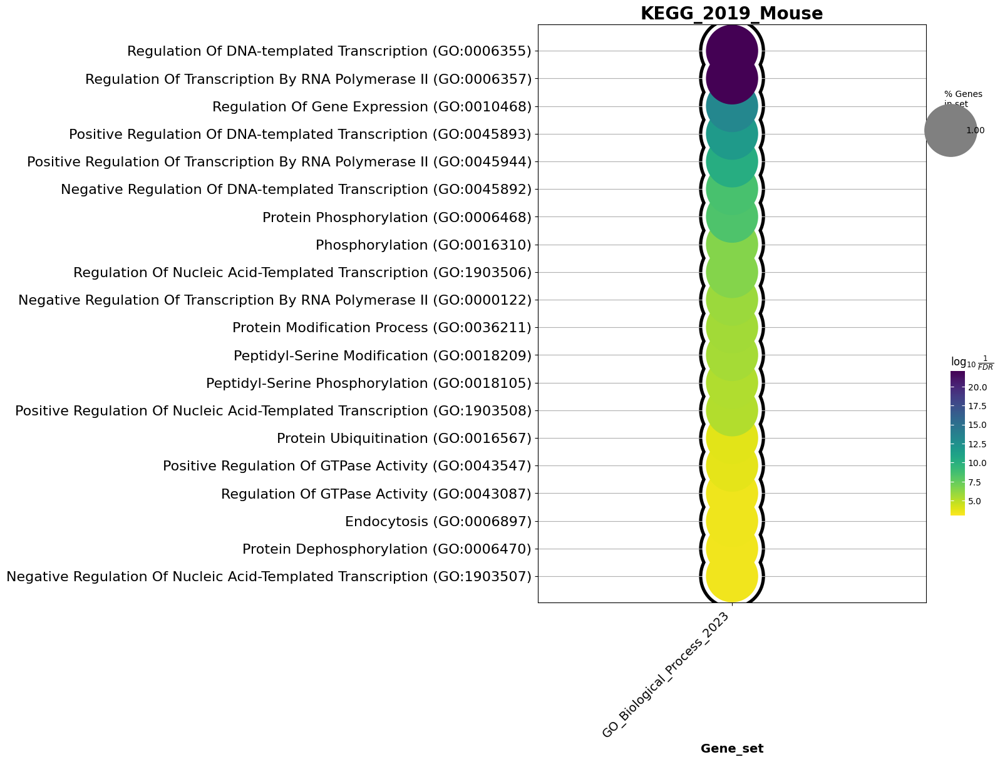

In [526]:
from gseapy import barplot, dotplot

# categorical scatterplot
ax = dotplot(enr.results,
              column="Adjusted P-value",
              x='Gene_set', # set x axis, so you could do a multi-sample/library comparsion
              size=10,
              top_term=20,
              figsize=(10,12),
              title = "KEGG_2019_Mouse",
              xticklabels_rot=45, # rotate xtick labels
              show_ring=True, # set to False to revmove outer ring
              marker='o',
             )

In [513]:
available_gene_sets = gseapy.get_library_name(organism='Mouse')  # Cambia a 'Mouse' si trabajas con ratones
available_gene_sets

['ARCHS4_Cell-lines',
 'ARCHS4_IDG_Coexp',
 'ARCHS4_Kinases_Coexp',
 'ARCHS4_TFs_Coexp',
 'ARCHS4_Tissues',
 'Achilles_fitness_decrease',
 'Achilles_fitness_increase',
 'Aging_Perturbations_from_GEO_down',
 'Aging_Perturbations_from_GEO_up',
 'Allen_Brain_Atlas_10x_scRNA_2021',
 'Allen_Brain_Atlas_down',
 'Allen_Brain_Atlas_up',
 'Azimuth_2023',
 'Azimuth_Cell_Types_2021',
 'BioCarta_2013',
 'BioCarta_2015',
 'BioCarta_2016',
 'BioPlanet_2019',
 'BioPlex_2017',
 'CCLE_Proteomics_2020',
 'CORUM',
 'COVID-19_Related_Gene_Sets',
 'COVID-19_Related_Gene_Sets_2021',
 'Cancer_Cell_Line_Encyclopedia',
 'CellMarker_2024',
 'CellMarker_Augmented_2021',
 'ChEA_2013',
 'ChEA_2015',
 'ChEA_2016',
 'ChEA_2022',
 'Chromosome_Location',
 'Chromosome_Location_hg19',
 'ClinVar_2019',
 'DGIdb_Drug_Targets_2024',
 'DSigDB',
 'Data_Acquisition_Method_Most_Popular_Genes',
 'DepMap_CRISPR_GeneDependency_CellLines_2023',
 'DepMap_WG_CRISPR_Screens_Broad_CellLines_2019',
 'DepMap_WG_CRISPR_Screens_Sanger_Cell

In [497]:
qval_cutoff = 0.1
mean_cutoff = 0.01
l2fc_cutoff = 0.25

tmp_df = big_df[big_df['time'] == 'D30']
D30_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
D30_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
D30_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])


tmp_df = big_df[big_df['time'] == 'Y1']
Y1_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
Y1_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
Y1_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])





tmp_df = big_df[big_df['time'] == 'diffxpy_control_D30_vs_Y1_all_data']
aging_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
aging_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
aging_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])

tmp_df = big_df[big_df['time'] == 'diffxpy_PIMQ_D30_vs_Y1_all_data']
pimq_aging_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
pimq_aging_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
pimq_aging_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])


In [502]:
aging_up

['LYPLA1',
 'TCEA1',
 'ATP6V1H',
 'RB1CC1',
 '4732440D04RIK',
 'PCMTD1',
 'VCPIP1',
 'SGK3',
 'SNHG6',
 'CSPP1',
 'ARFGEF1',
 'NCOA2',
 'LACTB2',
 'STAU2',
 'UBE2W',
 'GM28376',
 'JPH1',
 'TRAM2',
 'OGFRL1',
 'B3GAT2',
 'SMAP1',
 'FAM135A',
 'LMBRD1',
 'PHF3',
 'PTP4A1',
 'PRIM2',
 'ZFP451',
 'DST',
 'GM26788',
 'ARHGEF4',
 'FAM168B',
 'PLEKHB2',
 'HS6ST1',
 'UGGT1',
 'ARID5A',
 'KANSL3',
 'LMAN2L',
 'CNNM4',
 'CNNM3',
 'SEMA4C',
 'TMEM131',
 'INPP4A',
 'MGAT4A',
 '2010300C02RIK',
 'MITD1',
 'REV1',
 'AFF3',
 'NPAS2',
 'TBC1D8',
 'CNOT11',
 'RNF149',
 'MAP4K4',
 'GM16894',
 'IL1R1',
 'IL1RL2',
 'AI597479',
 'NCK2',
 'TPP2',
 'TEX30',
 'POGLUT2',
 'ERCC5',
 'WDR75',
 'NABP1',
 'STAT1',
 'GLS',
 'NAB1',
 'MFSD6',
 'ASNSD1',
 'GTF3C3',
 'PGAP1',
 'ANKRD44',
 'SF3B1',
 'COQ10B',
 'MOB4',
 'PLCL1',
 'BZW1',
 'CLK1',
 'ORC2',
 'FAM126B',
 'CFLAR',
 'CASP8',
 'TRAK2',
 'STRADB',
 'TMEM237',
 'ALS2',
 'GM973',
 'SUMO1',
 'NOP58',
 'BMPR2',
 'FAM117B',
 'CARF',
 'NBEAL1',
 'ABI2',
 'RAPH1',
 'I

In [498]:
[len(D30_up), len(D30_down), len(D30_ns), len(Y1_up), len(Y1_down), len(Y1_ns), len(aging_up), len(aging_down), len(aging_ns),
len(pimq_aging_up), len(pimq_aging_down), len(pimq_aging_ns)]

[4176, 187, 4382, 64, 19, 9710, 5502, 1192, 2717, 2134, 368, 6492]

In [499]:
g1_1 = list(set(D30_up).intersection(aging_up).intersection(pimq_aging_up))
g1_2 = list(set(D30_up).intersection(aging_up).intersection(pimq_aging_ns))
g1_3 = list(set(D30_up).intersection(aging_up).intersection(pimq_aging_down))
g2_1 = list(set(D30_up).intersection(aging_ns).intersection(pimq_aging_up))
g2_2 = list(set(D30_up).intersection(aging_ns).intersection(pimq_aging_ns))
g2_3 = list(set(D30_up).intersection(aging_ns).intersection(pimq_aging_down))
g3_1 = list(set(D30_down).intersection(aging_down).intersection(pimq_aging_up))
g3_2 = list(set(D30_down).intersection(aging_down).intersection(pimq_aging_ns))
g3_3 = list(set(D30_down).intersection(aging_down).intersection(pimq_aging_down))
g4_1 = list(set(D30_down).intersection(aging_ns).intersection(pimq_aging_up))
g4_2 = list(set(D30_down).intersection(aging_ns).intersection(pimq_aging_ns))
g4_3 = list(set(D30_down).intersection(aging_ns).intersection(pimq_aging_down))

[len(g1_1),
 len(g1_2),
 len(g1_3),
 len(g2_1),
 len(g2_2),
 len(g2_3),
 len(g3_1),
 len(g3_2),
 len(g3_3),
 len(g4_1),
 len(g4_2),
 len(g4_3)
]

[1331, 2072, 13, 2, 349, 32, 2, 99, 46, 2, 8, 1]

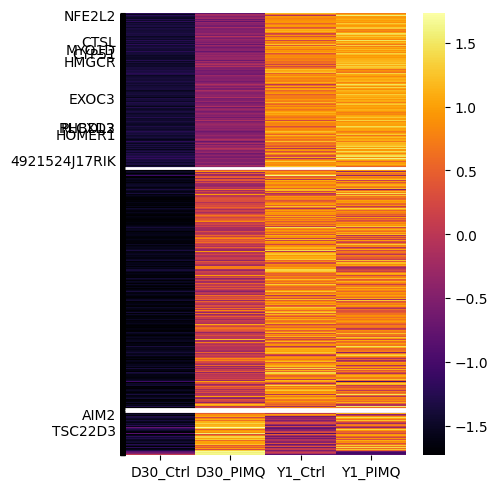

In [500]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# Combinar todos los genes en el orden deseado
all_genes = g1_1 + g1_2 + g1_3 + g2_1 + g2_2 + g2_3 

# Filtrar el dataframe original con ese orden
subdf = df[all_genes]

# Normalización z-score por columna
df_z = subdf.apply(zscore, axis=0)

plt.figure(figsize=(5, 5))

ax = sns.heatmap(df_z.T,
                 cmap = "inferno",
                 annot = False,
                 cbar = True,
                 yticklabels = False, 
                 xticklabels = True)



# Líneas horizontales en las posiciones cumulativas:
hline_positions = [
    len(g1_1), 
    len(g1_1) + len(g1_2), 
    len(g1_1) + len(g1_2) + len(g1_3),    
]

for pos in hline_positions:
    #ax.hlines(y=pos, xmin=0, xmax=df_z.shape[1], color='white', linewidth=2)
    ax.hlines(y=pos, xmin=0, xmax=df_z.shape[0], color='white', linewidth=2)

# Ahora, supongamos que tienes una lista de genes que quieres etiquetar
#genes = ['AIM2', 'CASP1', 'RUNX1', 'FOS', 'STAT3', 'GATA3'] 
genes = Y1_up

# Creamos las etiquetas de manera que solo se muestren si el gen está en 'genes'
#yticks = range(len(all_genes))
yticklabels = [g if g in genes else '' for g in all_genes]

ax.set_yticks(range(len(yticklabels)))
ax.set_yticklabels(yticklabels)

plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()


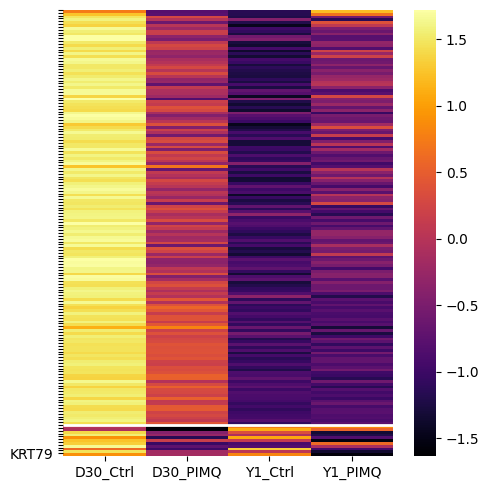

In [501]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# Combinar todos los genes en el orden deseado
all_genes = g3_1 + g3_2 + g3_3 + g4_1 + g4_2 + g4_3 

# Filtrar el dataframe original con ese orden
subdf = df[all_genes]

# Normalización z-score por columna
df_z = subdf.apply(zscore, axis=0)

plt.figure(figsize=(5, 5))

ax = sns.heatmap(df_z.T,
                 cmap = "inferno",
                 annot = False,
                 cbar = True,
                 yticklabels = False, 
                 xticklabels = True)



# Líneas horizontales en las posiciones cumulativas:
hline_positions = [
    len(g3_1) + len(g3_2) + len(g3_3),
]

for pos in hline_positions:
    ax.hlines(y=pos, xmin=0, xmax=df_z.shape[0], color='white', linewidth=2)

# Ahora, supongamos que tienes una lista de genes que quieres etiquetar
#genes = ['AIM2', 'CASP1', 'RUNX1', 'FOS', 'STAT3', 'GATA3'] 
genes = Y1_down

# Creamos las etiquetas de manera que solo se muestren si el gen está en 'genes'
#yticks = range(len(all_genes))
yticklabels = [g if g in genes else '' for g in all_genes]

ax.set_yticks(range(len(yticklabels)))
ax.set_yticklabels(yticklabels)

plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [443]:
qval_cutoff = 0.1
mean_cutoff = 0.01
l2fc_cutoff = 0.5

tmp_df = big_df[big_df['time'] == 'D30']
D30_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
D30_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
D30_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])


tmp_df = big_df[big_df['time'] == 'Y1']
Y1_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
Y1_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
Y1_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])


tmp_df = big_df[big_df['time'] == 'diffxpy_control_D30_vs_Y1_all_data']
aging_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
aging_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
aging_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])


tmp_df = big_df[big_df['time'] == 'diffxpy_control_D30_vs_Y1_all_data']
aging_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
aging_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
aging_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])

tmp_df = big_df[big_df['time'] == 'diffxpy_PIMQ_D30_vs_Y1_all_data']
pimq_aging_up = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] <= -l2fc_cutoff)]['gene'])
pimq_aging_down = list(tmp_df[(tmp_df['qval'] < qval_cutoff) & (tmp_df['mean'] >= mean_cutoff) & (tmp_df['log2fc'] >= l2fc_cutoff)]['gene'])
pimq_aging_ns = list(tmp_df[(tmp_df['qval'] >= 0.1) & (tmp_df['mean'] >= mean_cutoff) & (abs(tmp_df['log2fc']) <= 0.5)]['gene'])


In [445]:
g1_1 = list(set(D30_up).intersection(aging_up))
g1_2 = list(set(D30_up).intersection(aging_ns))
g1_3 = list(set(D30_up).intersection(aging_down))
g2_1 = list(set(D30_down).intersection(aging_up))
g2_2 = list(set(D30_down).intersection(aging_ns))
g2_3 = list(set(D30_down).intersection(aging_down))

[len(g1_1),
 len(g1_2),
 len(g1_3),
 len(g2_1),
 len(g2_2),
 len(g2_3)
]

[679, 117, 0, 0, 3, 25]

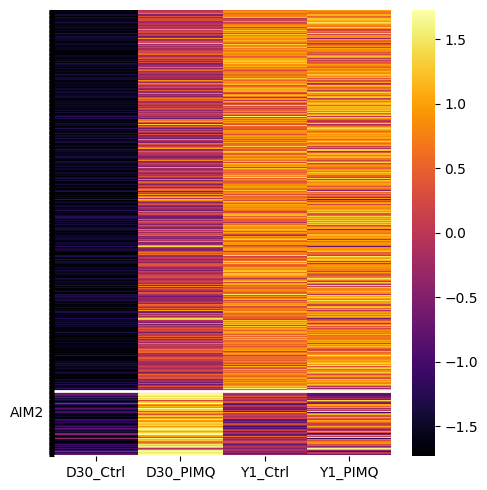

In [446]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# Combinar todos los genes en el orden deseado
all_genes = g1_1 + g1_2 + g1_3

# Filtrar el dataframe original con ese orden
subdf = df[all_genes]

# Normalización z-score por columna
df_z = subdf.apply(zscore, axis=0)

plt.figure(figsize=(5, 5))

ax = sns.heatmap(df_z.T,
                 cmap = "inferno",
                 annot = False,
                 cbar = True,
                 yticklabels = False, 
                 xticklabels = True)



# Líneas horizontales en las posiciones cumulativas:
hline_positions = [
    len(g1_1),
    len(g1_1) + len(g1_2),
    len(g1_1) + len(g1_2) + len(g1_3),  
]

for pos in hline_positions:
    #ax.hlines(y=pos, xmin=0, xmax=df_z.shape[1], color='white', linewidth=2)
    ax.hlines(y=pos, xmin=0, xmax=df_z.shape[0], color='white', linewidth=2)

# Ahora, supongamos que tienes una lista de genes que quieres etiquetar
#genes = ['AIM2', 'CASP1', 'RUNX1', 'FOS', 'STAT3', 'GATA3'] 
genes = Y1_up

# Creamos las etiquetas de manera que solo se muestren si el gen está en 'genes'
#yticks = range(len(all_genes))
yticklabels = [g if g in genes else '' for g in all_genes]

ax.set_yticks(range(len(yticklabels)))
ax.set_yticklabels(yticklabels)

plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()


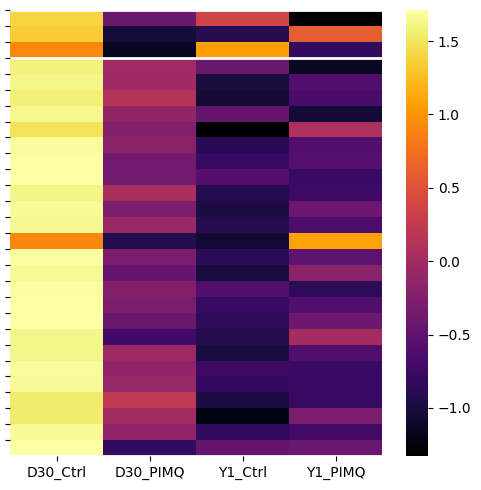

In [447]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# Combinar todos los genes en el orden deseado
all_genes = g2_1 + g2_2 + g2_3

# Filtrar el dataframe original con ese orden
subdf = df[all_genes]

# Normalización z-score por columna
df_z = subdf.apply(zscore, axis=0)

plt.figure(figsize=(5, 5))

ax = sns.heatmap(df_z.T,
                 cmap = "inferno",
                 annot = False,
                 cbar = True,
                 yticklabels = False, 
                 xticklabels = True)



# Líneas horizontales en las posiciones cumulativas:
hline_positions = [
    len(g2_1),
    len(g2_1) + len(g2_2),
    len(g2_1) + len(g2_2) + len(g2_3),  
]

for pos in hline_positions:
    #ax.hlines(y=pos, xmin=0, xmax=df_z.shape[1], color='white', linewidth=2)
    ax.hlines(y=pos, xmin=0, xmax=df_z.shape[0], color='white', linewidth=2)

# Ahora, supongamos que tienes una lista de genes que quieres etiquetar
#genes = ['AIM2', 'CASP1', 'RUNX1', 'FOS', 'STAT3', 'GATA3'] 
genes = Y1_down

# Creamos las etiquetas de manera que solo se muestren si el gen está en 'genes'
#yticks = range(len(all_genes))
yticklabels = [g if g in genes else '' for g in all_genes]

ax.set_yticks(range(len(yticklabels)))
ax.set_yticklabels(yticklabels)

plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()


/tmp/ipykernel_806/3496740972.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subdf['Condition'] = ['D30_Ctrl', 'D30_PIMQ', 'Y1_Ctrl', 'Y1_PIMQ']


<Axes: xlabel='Condition', ylabel='Expression'>

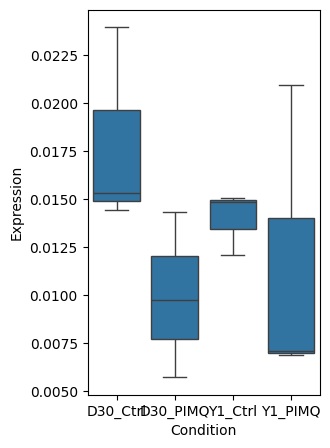

In [456]:
subdf = df[g2_2]
subdf['Condition'] = ['D30_Ctrl', 'D30_PIMQ', 'Y1_Ctrl', 'Y1_PIMQ']
df_long = subdf.melt(id_vars=['Condition'], var_name='Gene', value_name='Expression')
df_long['Z_Score'] = (df_long['Expression'] - df_long['Expression'].mean()) / df_long['Expression'].std()
plt.figure(figsize=(3, 5))
sns.boxplot(df_long, x = 'Condition', y = 'Expression')


In [124]:
[len(D30_up), len(D30_down), len(D30_ns), len(Y1_up), len(Y1_down), len(Y1_ns), len(Aging_ctrl_up), len(Aging_ctrl_down), len(Aging_ctrl_ns),
 len(Aging_pimq_up), len(Aging_pimq_down), len(Aging_pimq_ns)]

NameError: name 'Aging_ctrl_up' is not defined

In [41]:
len(set(D30_up).intersection(Aging_ctrl_up))
len(set(D30_up).intersection(Aging_ctrl_ns))
set(D30_up).intersection(Aging_ctrl_ns)

set()

In [22]:
set(D30_up).difference(Aging_ctrl_up)


{'1110032A03RIK',
 '1700096K18RIK',
 '1810030O07RIK',
 '2010001K21RIK',
 '2610037D02RIK',
 '2900060B14RIK',
 '3830406C13RIK',
 '4833439L19RIK',
 '4933434E20RIK',
 '5430416N02RIK',
 '5830416I19RIK',
 '9330162012RIK',
 '9530026P05RIK',
 'A330023F24RIK',
 'A730081D07RIK',
 'AADACL3',
 'ABCG1',
 'ABHD12',
 'ABHD4',
 'ABHD5',
 'ABRAXAS2',
 'ABTB1',
 'ACER2',
 'ACOX3',
 'ACSL1',
 'ADGRF4',
 'AIM2',
 'AKNAD1',
 'ALG9',
 'ALKBH3',
 'ANKRD46',
 'ANXA1',
 'AP3S2',
 'APH1A',
 'APMAP',
 'ARHGEF19',
 'ARL6IP6',
 'ART3',
 'ASCC1',
 'ASCL2',
 'ASH2L',
 'ATG5',
 'ATP13A2',
 'ATP6V1C2',
 'ATP6V1D',
 'ATP6V1E1',
 'ATXN10',
 'B4GALNT1',
 'BCAR1',
 'BLOC1S5',
 'BMP7',
 'BRCC3',
 'BRI3',
 'BUD13',
 'CAAA01118383.1',
 'CABIN1',
 'CACNA2D2',
 'CANT1',
 'CASD1',
 'CBS',
 'CBWD1',
 'CCDC148',
 'CCDC25',
 'CCDC71',
 'CCDC90B',
 'CCND3',
 'CCSER1',
 'CDCA7',
 'CDCA7L',
 'CDIPT',
 'CDK16',
 'CDK7',
 'CENPB',
 'CEP112',
 'CEP41',
 'CFAP300',
 'CHMP5',
 'CLIP4',
 'COL8A1',
 'CORO7',
 'COX16',
 'COX7A2L',
 'CPEB3',


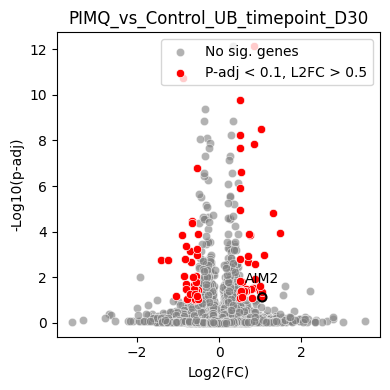

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 0.5
mean_cutoff = 0.02

# Load data
file = 'diffxpy_PIMQ_vs_Control_UB_timepoint_D30.csv'
df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in df.columns:
    gene_column = 'Gene'
elif 'gene' in df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Convert gene names to uppercase for consistent comparison
df[gene_column] = df[gene_column].str.upper()

# Calculate -log10(qval)
df['logqval'] = -np.log10(df['qval'] + 1e-22)
df = df[df['logqval'] < 15]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='log2fc', y='logqval', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = df[
    (df['mean'] > mean_cutoff) & 
    (df['qval'] < qval_cutoff) & 
    (np.abs(df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='log2fc', y='logqval', color='red', label='P-adj < 0.1, L2FC > 0.5')

# Highlight specific genes in blue
blue_genes = ['AIM2']  # Only two genes
blue_genes = [gene.upper() for gene in blue_genes]  # Convert to uppercase
highlight_blue = df[df[gene_column].isin(blue_genes)]
sns.scatterplot(data=highlight_blue, x='log2fc', y='logqval', edgecolor = 'black', facecolors='none',linewidth=1.5)

# Add labels for blue genes
for _, row in highlight_blue.iloc[[0]].iterrows():
    plt.text(
        row['log2fc'], 
        row['logqval'] + 0.5, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )

# Configure plot settings
#plt.xscale('log')
plt.xlabel('Log2(FC)')
plt.ylabel('-Log10(p-adj)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.legend()
plt.tight_layout()
plt.show()


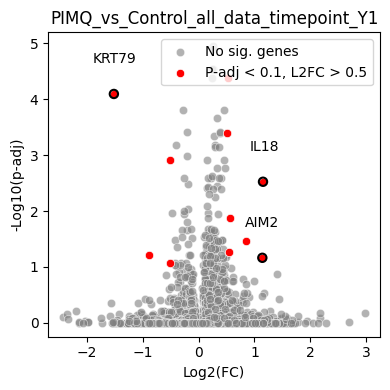

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 0.5
mean_cutoff = 0.01

# Load data
file = 'diffxpy_PIMQ_vs_Control_all_data_timepoint_Y1.csv'
df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in df.columns:
    gene_column = 'Gene'
elif 'gene' in df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Convert gene names to uppercase for consistent comparison
df[gene_column] = df[gene_column].str.upper()

# Calculate -log10(qval)
df['logqval'] = -np.log10(df['qval'] + 1e-22)
df = df[df['logqval'] < 15]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='log2fc', y='logqval', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = df[
    (df['mean'] > mean_cutoff) & 
    (df['qval'] < qval_cutoff) & 
    (np.abs(df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='log2fc', y='logqval', color='red', label='P-adj < 0.1, L2FC > 0.5')

# Highlight specific genes in blue
blue_genes = ['AIM2', 'IL18', 'KRT79']  # Only two genes
blue_genes = [gene.upper() for gene in blue_genes]  # Convert to uppercase
highlight_blue = df[df[gene_column].isin(blue_genes)]
sns.scatterplot(data=highlight_blue, x='log2fc', y='logqval', edgecolor = 'black', facecolors='none',linewidth=1.5)

# Add labels for blue genes
for _, row in highlight_blue.iloc[[0]].iterrows():
    plt.text(
        row['log2fc'], 
        row['logqval'] + 0.5, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
for _, row in highlight_blue.iloc[[1]].iterrows():
    plt.text(
        row['log2fc'] + 0.02, 
        row['logqval'] + 0.5, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )

for _, row in highlight_blue.iloc[[2]].iterrows():
    plt.text(
        row['log2fc'] + 0.02, 
        row['logqval'] + 0.5, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
# Configure plot settings
#plt.xscale('log')
plt.xlabel('Log2(FC)')
plt.ylabel('-Log10(p-adj)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.legend()
plt.tight_layout()
plt.show()


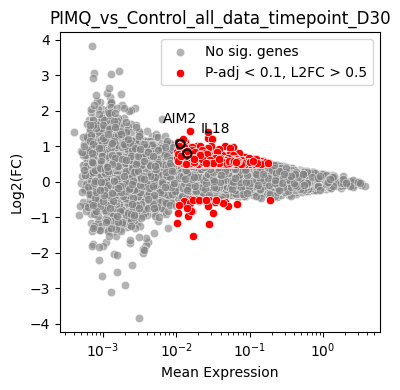

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 0.5
mean_cutoff = 0.01

# Load data
file = 'diffxpy_PIMQ_vs_Control_all_data_timepoint_D30.csv'
df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in df.columns:
    gene_column = 'Gene'
elif 'gene' in df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Convert gene names to uppercase for consistent comparison
df[gene_column] = df[gene_column].str.upper()

# Calculate -log10(qval)
df['logqval'] = -np.log10(df['qval'] + 1e-22)
df = df[df['logqval'] < 15]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='mean', y='log2fc', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = df[
    (df['mean'] > mean_cutoff) & 
    (df['qval'] < qval_cutoff) & 
    (np.abs(df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='mean', y='log2fc', color='red', label='P-adj < 0.1, L2FC > 0.5')

# Highlight specific genes in blue
blue_genes = ['AIM2', 'IL18']  # Only two genes
blue_genes = [gene.upper() for gene in blue_genes]  # Convert to uppercase
highlight_blue = df[df[gene_column].isin(blue_genes)]
sns.scatterplot(data=highlight_blue, x='mean', y='log2fc', edgecolor = 'black', facecolors='none',linewidth=1.5)

# Add labels for blue genes
for _, row in highlight_blue.iloc[[0]].iterrows():
    plt.text(
        row['mean'], 
        row['log2fc'] + 0.5, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
for _, row in highlight_blue.iloc[[1]].iterrows():
    plt.text(
        row['mean'] + 0.02, 
        row['log2fc'] + 0.5, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
# Configure plot settings
plt.xscale('log')
plt.xlabel('Mean Expression')
plt.ylabel('Log2(FC)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
highlight

,Unnamed: 0,gene,pval,qval,log2fc,mean,zero_mean,grad,coef_mle,coef_sd,ll,logqval
37,37,GM28376,0.007,0.024,0.703,0.012,False,0.008,0.703,0.259,-133.985,1.627
84,84,SEMA4C,0.002,0.010,0.814,0.011,False,0.000,0.814,0.268,-299.541,1.995
91,91,INPP4A,0.010,0.032,0.514,0.020,False,0.021,0.514,0.198,-357.530,1.496
94,94,MGAT4A,0.011,0.035,0.700,0.011,False,0.012,0.700,0.274,-19.313,1.459
119,119,AI597479,0.022,0.062,0.506,0.016,False,0.016,0.506,0.220,-92.637,1.210
121,121,NCK2,0.001,0.003,0.592,0.026,False,0.162,0.592,0.174,-432.706,2.470
125,125,POGLUT2,0.018,0.053,0.655,0.010,False,0.000,0.655,0.276,-279.099,1.277
137,137,NABP1,0.000,0.000,0.535,0.069,False,0.062,0.535,0.107,-781.020,5.120
140,140,STAT1,0.000,0.000,0.629,0.067,False,0.025,0.629,0.109,-218.561,6.715
152,152,OSGEPL1,0.027,0.073,0.620,0.010,False,0.000,0.620,0.280,-272.743,1.137


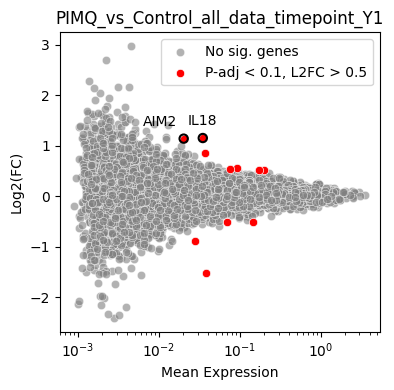

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 0.5
mean_cutoff = 0.01

# Load data
file = 'diffxpy_PIMQ_vs_Control_all_data_timepoint_Y1.csv'
df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in df.columns:
    gene_column = 'Gene'
elif 'gene' in df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Convert gene names to uppercase for consistent comparison
df[gene_column] = df[gene_column].str.upper()

# Calculate -log10(qval)
df['logqval'] = -np.log10(df['qval'] + 1e-22)
df = df[df['logqval'] < 15]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='mean', y='log2fc', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = df[
    (df['mean'] > mean_cutoff) & 
    (df['qval'] < qval_cutoff) & 
    (np.abs(df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='mean', y='log2fc', color='red', label='P-adj < 0.1, L2FC > 0.5')

# Highlight specific genes in blue
blue_genes = ['AIM2', 'IL18']  # Only two genes
blue_genes = [gene.upper() for gene in blue_genes]  # Convert to uppercase
highlight_blue = df[df[gene_column].isin(blue_genes)]
sns.scatterplot(data=highlight_blue, x='mean', y='log2fc', edgecolor = 'black', facecolors='none',linewidth=1.5)

# Add labels for blue genes
for _, row in highlight_blue.iloc[[0]].iterrows():
    plt.text(
        row['mean'] - 0.01, 
        row['log2fc'] + 0.2, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
for _, row in highlight_blue.iloc[[1]].iterrows():
    plt.text(
        row['mean'] , 
        row['log2fc'] + 0.2, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
# Configure plot settings
plt.xscale('log')
plt.xlabel('Mean Expression')
plt.ylabel('Log2(FC)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.legend()
plt.tight_layout()
plt.show()


In [27]:
highlight.sort_values('log2fc',ascending=False)

,Unnamed: 0,gene,pval,qval,log2fc,mean,zero_mean,grad,coef_mle,coef_sd,ll,logqval
6555,6555,IL18,0.000,0.003,1.154,0.035,False,0.000,1.154,0.258,-346.271,2.523
642,642,AIM2,0.001,0.069,1.142,0.020,False,0.000,1.142,0.337,-231.907,1.164
5404,5404,PLK1,0.000,0.034,0.857,0.038,False,0.004,0.857,0.230,-384.607,1.467
2951,2951,TENT5B,0.000,0.013,0.562,0.092,False,0.000,0.562,0.139,-738.185,1.876
5514,5514,BUB3,0.000,0.054,0.537,0.076,False,0.000,0.537,0.152,-668.831,1.269
1950,1950,FDPS,0.000,0.000,0.527,0.199,False,0.000,0.527,0.094,-1280.361,4.378
10959,10959,PLCXD2,0.000,0.000,0.512,0.170,False,0.000,0.512,0.101,-1142.389,3.398
1867,1867,MLF1,0.000,0.001,-0.505,0.145,False,0.142,-0.505,0.107,-537.472,2.919
7595,7595,SRGAP1,0.001,0.085,-0.509,0.070,False,0.064,-0.509,0.154,-505.728,1.070
7220,7220,SLC35F1,0.001,0.060,-0.892,0.028,False,0.028,-0.892,0.257,-215.152,1.220


In [178]:
df[ (df['mean'] > mean_cutoff) & (df['qval'] < qval_cutoff) & (np.abs(df['log2fc']) > log2fc_cutoff)][['gene', 'qval', 'log2fc', 'mean']].sort_values('log2fc', ascending = False)


,gene,qval,log2fc,mean
6555,IL18,0.003,1.154,0.035
642,AIM2,0.069,1.142,0.020
5404,PLK1,0.034,0.857,0.038
2951,TENT5B,0.013,0.562,0.092
5514,BUB3,0.054,0.537,0.076
1950,FDPS,0.000,0.527,0.199
10959,PLCXD2,0.000,0.512,0.170
1867,MLF1,0.001,-0.505,0.145
7595,SRGAP1,0.085,-0.509,0.070
7220,SLC35F1,0.060,-0.892,0.028


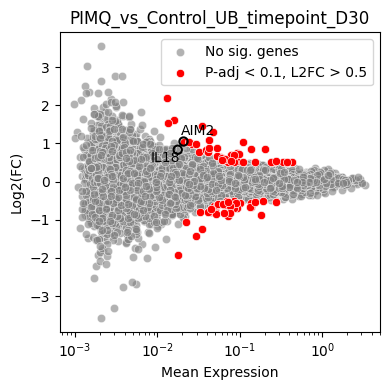

In [179]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 0.5
mean_cutoff = 0.01

# Load data
file = 'diffxpy_PIMQ_vs_Control_UB_timepoint_D30.csv'
df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in df.columns:
    gene_column = 'Gene'
elif 'gene' in df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Convert gene names to uppercase for consistent comparison
df[gene_column] = df[gene_column].str.upper()

# Calculate -log10(qval)
df['logqval'] = -np.log10(df['qval'] + 1e-22)
df = df[df['logqval'] < 15]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='mean', y='log2fc', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = df[
    (df['mean'] > mean_cutoff) & 
    (df['qval'] < qval_cutoff) & 
    (np.abs(df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='mean', y='log2fc', color='red', label='P-adj < 0.1, L2FC > 0.5')

# Highlight specific genes in blue
blue_genes = ['AIM2', 'IL18']  # Only two genes
blue_genes = [gene.upper() for gene in blue_genes]  # Convert to uppercase
highlight_blue = df[df[gene_column].isin(blue_genes)]
sns.scatterplot(data=highlight_blue, x='mean', y='log2fc', edgecolor = 'black', facecolors='none',linewidth=1.5)

# Add labels for blue genes
for _, row in highlight_blue.iloc[[0]].iterrows():
    plt.text(
        row['mean']+0.01, 
        row['log2fc'] + 0.1, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
for _, row in highlight_blue.iloc[[1]].iterrows():
    plt.text(
        row['mean'] - 0.005, 
        row['log2fc'] - 0.4, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
# Configure plot settings
plt.xscale('log')
plt.xlabel('Mean Expression')
plt.ylabel('Log2(FC)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.legend()
plt.tight_layout()
plt.show()


In [180]:
df[ (df['mean'] > mean_cutoff) & (df['qval'] < qval_cutoff) & (np.abs(df['log2fc']) > log2fc_cutoff)][['gene', 'qval', 'log2fc', 'mean']].sort_values('log2fc', ascending = False)


,gene,qval,log2fc,mean
12280,IIGP1,0.040,2.202,0.013
2700,GM49890,0.024,1.602,0.016
9197,SLC10A1,0.058,1.542,0.013
4114,D730045B01RIK,0.000,1.468,0.035
3300,STEAP4,0.000,1.311,0.048
9459,ELMO1,0.001,1.078,0.042
661,AIM2,0.076,1.049,0.021
7252,SAMD5,0.042,1.034,0.024
4279,GPNMB,0.000,1.027,0.109
4115,1700028E10RIK,0.041,0.990,0.026


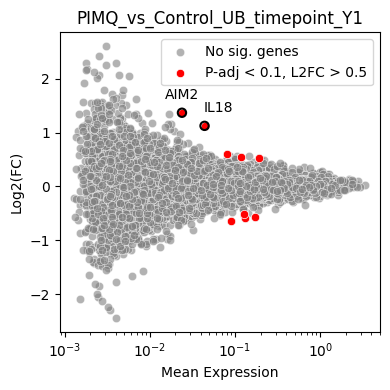

In [181]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 0.5
mean_cutoff = 0.01

# Load data
file = 'diffxpy_PIMQ_vs_Control_UB_timepoint_Y1.csv'
df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in df.columns:
    gene_column = 'Gene'
elif 'gene' in df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Convert gene names to uppercase for consistent comparison
df[gene_column] = df[gene_column].str.upper()

# Calculate -log10(qval)
df['logqval'] = -np.log10(df['qval'] + 1e-22)
df = df[df['logqval'] < 15]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='mean', y='log2fc', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = df[
    (df['mean'] > mean_cutoff) & 
    (df['qval'] < qval_cutoff) & 
    (np.abs(df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='mean', y='log2fc', color='red', label='P-adj < 0.1, L2FC > 0.5')

# Highlight specific genes in blue
blue_genes = ['AIM2', 'IL18']  # Only two genes
blue_genes = [gene.upper() for gene in blue_genes]  # Convert to uppercase
highlight_blue = df[df[gene_column].isin(blue_genes)]
sns.scatterplot(data=highlight_blue, x='mean', y='log2fc', edgecolor = 'black', facecolors='none',linewidth=1.5)

# Add labels for blue genes
for _, row in highlight_blue.iloc[[0]].iterrows():
    plt.text(
        row['mean'], 
        row['log2fc'] + 0.2, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
for _, row in highlight_blue.iloc[[1]].iterrows():
    plt.text(
        row['mean'] + 0.02, 
        row['log2fc'] + 0.2, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
# Configure plot settings
plt.xscale('log')
plt.xlabel('Mean Expression')
plt.ylabel('Log2(FC)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.legend()
plt.tight_layout()
plt.show()


In [182]:
df[ (df['mean'] > mean_cutoff) & (df['qval'] < qval_cutoff) & (np.abs(df['log2fc']) > log2fc_cutoff)][['gene', 'qval', 'log2fc', 'mean']].sort_values('log2fc', ascending = False)


,gene,qval,log2fc,mean
623,AIM2,0.092,1.370,0.024
6397,IL18,0.017,1.127,0.044
6178,MMP3,0.095,0.605,0.082
9853,DGKH,0.047,0.549,0.117
9793,CLU,0.003,0.526,0.192
8493,ZFP750,0.039,-0.516,0.127
1790,POSTN,0.030,-0.528,0.129
1825,MLF1,0.002,-0.562,0.171
5243,GM45792,0.007,-0.586,0.131
7407,SRGAP1,0.029,-0.644,0.090


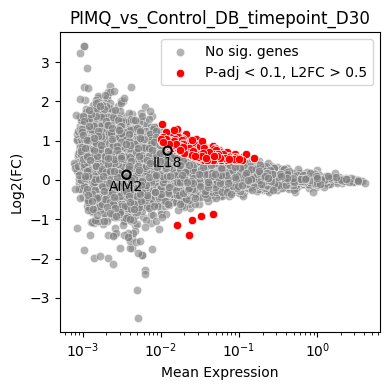

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 0.5
mean_cutoff = 0.01

# Load data
file = 'diffxpy_PIMQ_vs_Control_DB_timepoint_D30.csv'
df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in df.columns:
    gene_column = 'Gene'
elif 'gene' in df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Convert gene names to uppercase for consistent comparison
df[gene_column] = df[gene_column].str.upper()

# Calculate -log10(qval)
df['logqval'] = -np.log10(df['qval'] + 1e-22)
df = df[df['logqval'] < 15]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='mean', y='log2fc', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = df[
    (df['mean'] > mean_cutoff) & 
    (df['qval'] < qval_cutoff) & 
    (np.abs(df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='mean', y='log2fc', color='red', label='P-adj < 0.1, L2FC > 0.5')

# Highlight specific genes in blue
blue_genes = ['AIM2', 'IL18']  # Only two genes
blue_genes = [gene.upper() for gene in blue_genes]  # Convert to uppercase
highlight_blue = df[df[gene_column].isin(blue_genes)]
sns.scatterplot(data=highlight_blue, x='mean', y='log2fc', edgecolor = 'black', facecolors='none',linewidth=1.5)

# Add labels for blue genes
for _, row in highlight_blue.iloc[[0]].iterrows():
    plt.text(
        row['mean'], 
        row['log2fc'] - 0.5, 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )
for _, row in highlight_blue.iloc[[1]].iterrows():
    plt.text(
        row['mean'], 
        row['log2fc'] - 0.5 , 
        row[gene_column], 
        fontsize=10, 
        color='black', 
        ha='center', 
        va='bottom'
    )


# Configure plot settings
plt.xscale('log')
plt.xlabel('Mean Expression')
plt.ylabel('Log2(FC)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.legend()
plt.tight_layout()
plt.show()


In [184]:
df[ (df['mean'] > mean_cutoff) & (df['qval'] < qval_cutoff) & (np.abs(df['log2fc']) > log2fc_cutoff)][['gene', 'qval', 'log2fc', 'mean']].sort_values('log2fc', ascending = False)


,gene,qval,log2fc,mean
7759,HIST1H2BE,0.017,1.429,0.010
5677,CEP162,0.005,1.285,0.016
6899,WFDC21,0.047,1.263,0.015
5490,NPAT,0.010,1.232,0.015
5534,CLK3,0.014,1.214,0.014
1712,FLG2,0.066,1.213,0.016
7598,CCDC88C,0.027,1.209,0.012
1465,PDE7A,0.002,1.183,0.021
2503,EXTL1,0.038,1.155,0.011
2965,NUP54,0.016,1.154,0.015


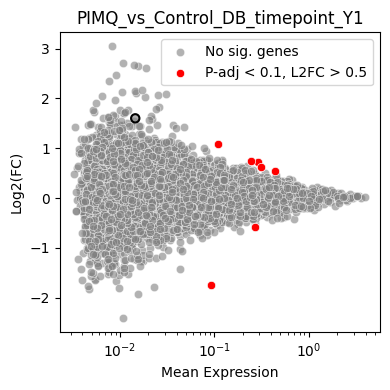

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initial configuration
qval_cutoff = 0.1
log2fc_cutoff = 0.5
mean_cutoff = 0.01

# Load data
file = 'diffxpy_PIMQ_vs_Control_DB_timepoint_Y1.csv'
df = pd.read_csv('../intermediate_outputs/strict_diffxpy/' + file)

# Ensure the gene column is correctly identified
if 'Gene' in df.columns:
    gene_column = 'Gene'
elif 'gene' in df.columns:
    gene_column = 'gene'
else:
    raise ValueError("Gene column not found in the DataFrame.")

# Convert gene names to uppercase for consistent comparison
df[gene_column] = df[gene_column].str.upper()

# Calculate -log10(qval)
df['logqval'] = -np.log10(df['qval'] + 1e-22)
df = df[df['logqval'] < 15]

# Create the base plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='mean', y='log2fc', color='grey', alpha=0.6, label='No sig. genes')

# Highlight significant genes
highlight = df[
    (df['mean'] > mean_cutoff) & 
    (df['qval'] < qval_cutoff) & 
    (np.abs(df['log2fc']) > log2fc_cutoff)
]
sns.scatterplot(data=highlight, x='mean', y='log2fc', color='red', label='P-adj < 0.1, L2FC > 0.5')

# Highlight specific genes in blue
blue_genes = ['AIM2', 'IL18']  # Only two genes
blue_genes = [gene.upper() for gene in blue_genes]  # Convert to uppercase
highlight_blue = df[df[gene_column].isin(blue_genes)]
sns.scatterplot(data=highlight_blue, x='mean', y='log2fc', edgecolor = 'black', facecolors='none',linewidth=1.5)


    
# Configure plot settings
plt.xscale('log')
plt.xlabel('Mean Expression')
plt.ylabel('Log2(FC)')
plt.title(file.split('diffxpy_')[1].split('.csv')[0])
plt.legend()
plt.tight_layout()
plt.show()


In [187]:
df[ (df['mean'] > mean_cutoff) & (df['qval'] < qval_cutoff) & (np.abs(df['log2fc']) > log2fc_cutoff)][['gene', 'qval', 'log2fc', 'mean']].sort_values('log2fc', ascending = False)


,gene,qval,log2fc,mean
3315,PAFAH1B3,0.053,1.085,0.110
7200,RBX1,0.015,0.739,0.247
1378,FDPS,0.006,0.733,0.289
7967,TOMM6,0.019,0.622,0.313
2641,RAN,0.015,0.537,0.435
7584,NRIP1,0.100,-0.590,0.271
7323,KRT79,0.015,-1.751,0.091


/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


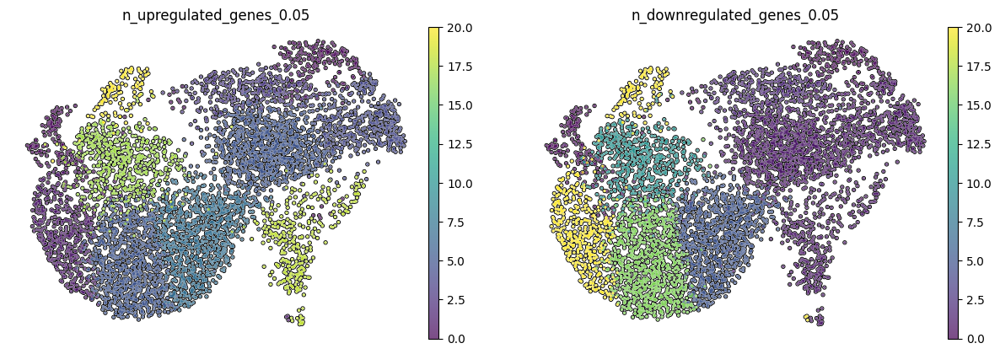

In [49]:
sc.pl.umap(adata_sub, color=['n_upregulated_genes_0.05', 'n_downregulated_genes_0.05'], frameon  = False, s = 20, add_outline = True, legend_loc = 'on data', vmax = 20)  


/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


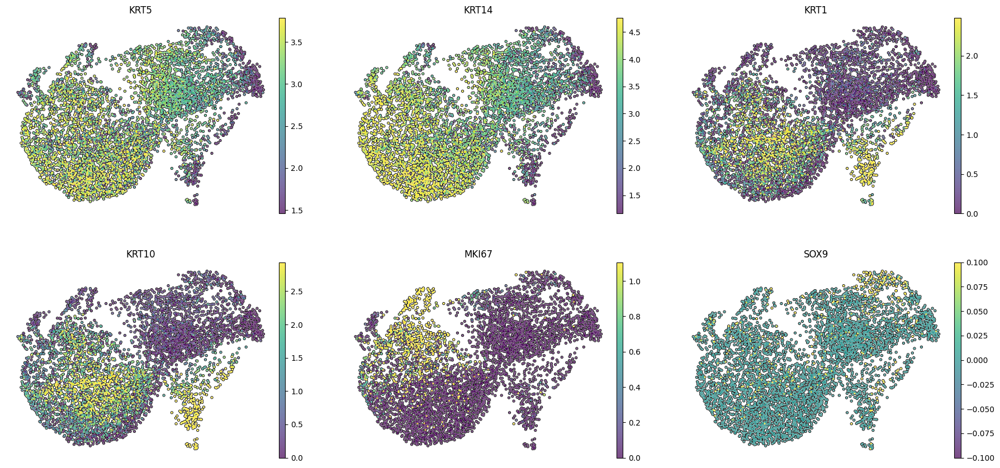

In [63]:
sc.pl.umap(adata_sub, color=['KRT5', 'KRT14', 'KRT1', 'KRT10', 'MKI67', 'SOX9'], ncols =3 , frameon  = False, s = 20, add_outline = True, legend_loc = 'on data', vmin = 'p10', vmax = 'p90')  


/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


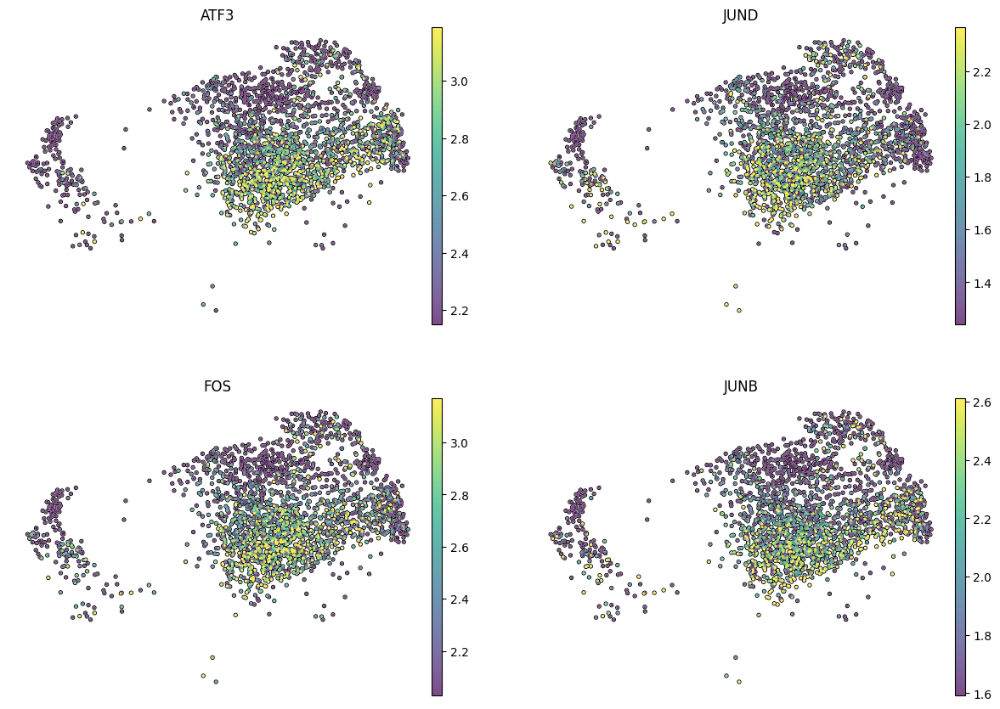

/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


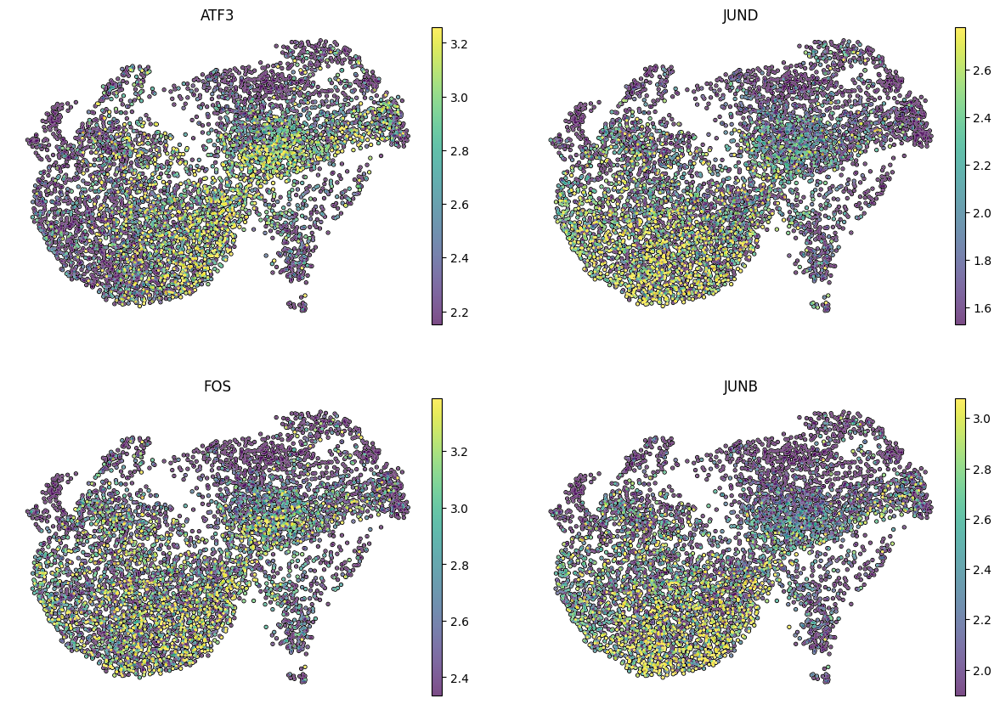

Error in atexit._run_exitfuncs:
Traceback (most recent call last):
  File "/home/lufesu/.local/lib/python3.8/site-packages/IPython/core/history.py", line 834, in writeout_cache
    self._writeout_input_cache(conn)
  File "/home/lufesu/.local/lib/python3.8/site-packages/IPython/core/history.py", line 817, in _writeout_input_cache
    conn.execute("INSERT INTO history VALUES (?, ?, ?, ?)",
sqlite3.DatabaseError: database disk image is malformed


In [68]:
sc.pl.umap(adata_sub[adata_sub.obs['sub_cluster3'].isin(['UB_1', 'UB_2', 'UB_3', 'uHFSC', 'UB_Krt6a'])], color=['ATF3', 'JUND', 'FOS', 'JUNB'], ncols =2 , frameon  = False, s = 20, add_outline = True, legend_loc = 'on data', vmin = 'p40', vmax = 'p90')  
sc.pl.umap(adata_sub, color=['ATF3', 'JUND', 'FOS', 'JUNB'], ncols =2 , frameon  = False, s = 20, add_outline = True, legend_loc = 'on data', vmin = 'p40', vmax = 'p90')  


/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


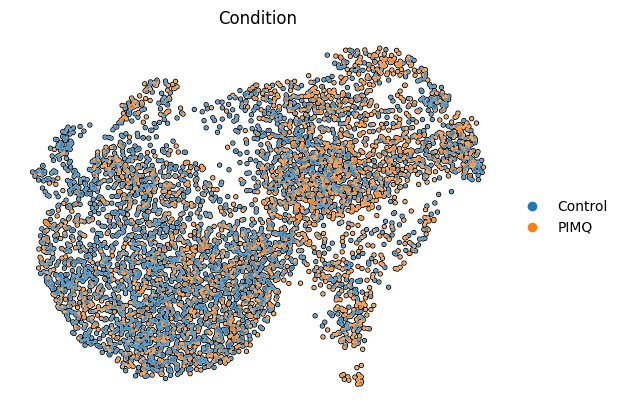

/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


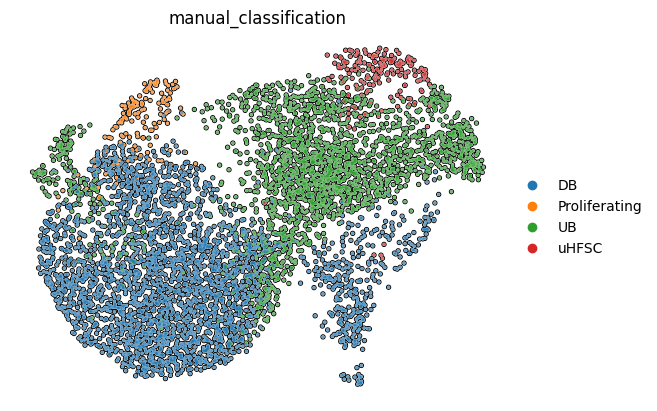

/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


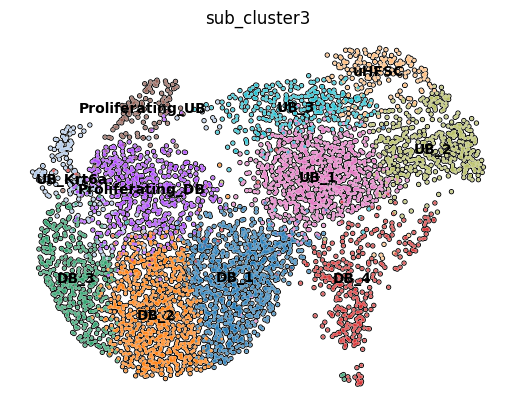

In [57]:
sc.pl.umap(adata_sub, color=['Condition'], frameon  = False, s = 20, add_outline = True)  
sc.pl.umap(adata_sub, color=['manual_classification'], frameon  = False, s = 20, add_outline = True)  

sc.pl.umap(adata_sub, color=['sub_cluster3'], frameon  = False, s = 20, add_outline = True, legend_loc = 'on data', vmax = 20)  
#manual_classification

In [52]:
q_val_cutoff = 0.05
logfc_cutoff = 1
for file in files:
    name = file.split('selected_')[1].split('_between_conditions')[0]
    if name in ['DB_1', 'DB_2', 'DB_3', 'DB_4', 'Proliferating_DB', 'Proliferating_UB', 'UB_1','UB_2', 'UB_3']:
        df = pd.read_csv('../intermediate_outputs/diffxpy_output/' + file)
        df = df[(df['qval'] <= q_val_cutoff) & (df['log2fc'] > logfc_cutoff) & (df['mean'] > 0.005)].sort_values('mean', ascending = False)
        print(name)

        print(df[['gene', 'pval', 'qval', 'log2fc', 'mean']])
    

DB_1
           gene      pval      qval      log2fc      mean
4295    CYP3A13  0.000426  0.002874    1.050541  0.050602
2439      GSTM2  0.001757  0.011804    1.019824  0.044070
10615     F2RL1  0.001598  0.010745    1.157790  0.035540
9851    PPP2R5E  0.000826  0.005566    1.400712  0.028981
14221      NBDY  0.003878  0.025986    1.531700  0.019539
13701      LCOR  0.004248  0.028428    1.878852  0.015071
7447      FBXO9  0.005355  0.035802    2.282612  0.012707
11223  AW549877  0.000000  0.000000  283.913085  0.006541
DB_2
               gene      pval      qval    log2fc      mean
326           ITM2C  0.005893  0.034463  1.097135  0.029706
9164            HLF  0.003950  0.023129  1.264783  0.026884
5887  1600010M07RIK  0.004566  0.026724  1.233612  0.025898
3187           SFPQ  0.005721  0.033470  1.207408  0.024885
6398          UFSP2  0.007215  0.042162  1.888126  0.011597
DB_3
                gene      pval      qval      log2fc      mean
11883           YDJC  0.008027  0.044832

In [23]:
q_val_cutoff = 0.05

for file in files:
    if name == 'Proliferating':
            name = 'Proliferating_UB'
    if name == 'DB_Krt6a':
            name = 'UB_Krt6a'
    print(name)
        
    name = file.split('selected_')[1].split('_between_conditions')[0]
    df = pd.read_csv('../intermediate_outputs/diffxpy_output/' + file)
    df = df[(df['qval'] <= q_val_cutoff) & (df['log2fc'] <= -logfc_cutoff) & (df['mean'] > 0.01)].sort_values('mean', ascending = False)
    print(name)
    
    print(df)
    

uHFSC
DB_0
Empty DataFrame
Columns: [Unnamed: 0, gene, pval, qval, log2fc, mean, zero_mean, grad, coef_mle, coef_sd, ll]
Index: []
DB_0
DB_1
Empty DataFrame
Columns: [Unnamed: 0, gene, pval, qval, log2fc, mean, zero_mean, grad, coef_mle, coef_sd, ll]
Index: []
DB_1
DB_3
     Unnamed: 0   gene      pval      qval    log2fc      mean  zero_mean  \
424         424  CENPF  0.000141  0.047265 -1.717816  0.141295      False   

             grad  coef_mle   coef_sd          ll  
424  4.226128e-11 -1.717816  0.451347 -131.380015  
DB_3
DB_4
      Unnamed: 0   gene  pval  qval      log2fc     mean  zero_mean      grad  \
1519        1519  HINT3   0.0   0.0 -297.776029  0.04056      False  0.040982   

        coef_mle        coef_sd        ll  
1519 -297.776029  2.222759e-162 -4.292184  
DB_4
DB_5
Empty DataFrame
Columns: [Unnamed: 0, gene, pval, qval, log2fc, mean, zero_mean, grad, coef_mle, coef_sd, ll]
Index: []
DB_5
DB_6
Empty DataFrame
Columns: [Unnamed: 0, gene, pval, qval, log2fc, mean,

/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


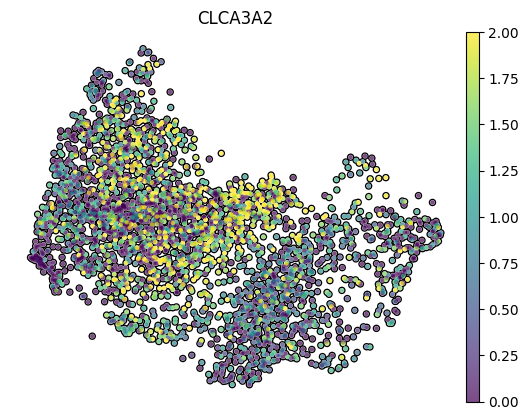

/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


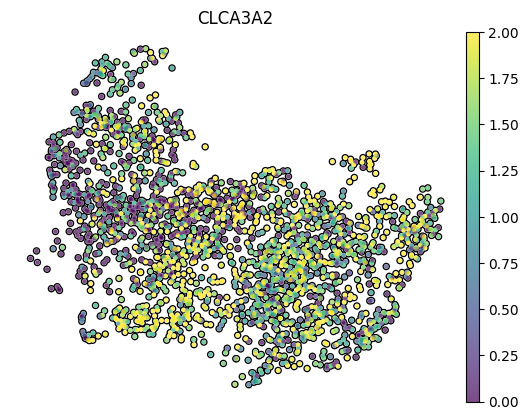

In [68]:
sc.pl.umap(adata_sub[adata_sub.obs['Condition'] == 'Control'], color = 'CLCA3A2', frameon  = False, s = 40, add_outline = True, legend_loc = 'on data', vmax =2)  
sc.pl.umap(adata_sub[adata_sub.obs['Condition'] == 'PIMQ'], color = 'CLCA3A2', frameon  = False, s = 40, add_outline = True, legend_loc = 'on data', vmax =2)  


In [43]:
df.shape[0]

5355

In [35]:
file = files[11]
print(file)
df = pd.read_csv('../intermediate_outputs/diffxpy_output/' + file)
df[(df['qval'] <= 0.15) & (df['log2fc'] > 0)].sort_values('mean', ascending = False)


group_selected_UB_2_between_conditions_D30.csv


,Unnamed: 0,gene,pval,qval,log2fc,mean,zero_mean,grad,coef_mle,coef_sd,ll
1100,1100,KLF4,4.579892e-05,8.175108e-02,0.487505,1.186319,False,3.445731e-05,0.487505,0.119601,-333.838505
997,997,CLCA3A2,1.424603e-10,7.628747e-07,0.893593,0.999890,False,8.769967e-01,0.893593,0.139336,-15.216187
5067,5067,ANXA1,1.334310e-05,3.572615e-02,0.675945,0.803943,False,1.686593e-09,0.675945,0.155233,-294.766686


/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_utils.py:429: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


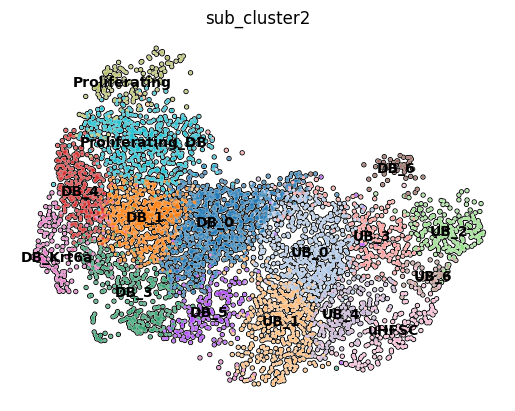

/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


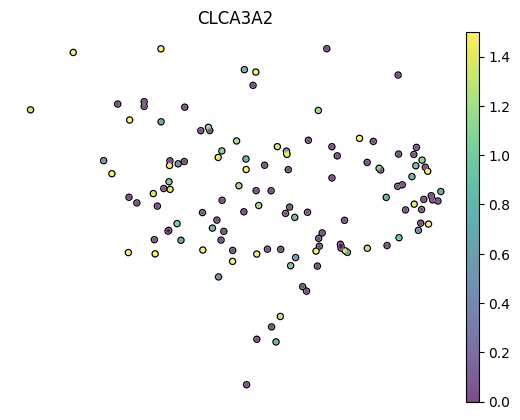

/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:368: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/home/lufesu/.local/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


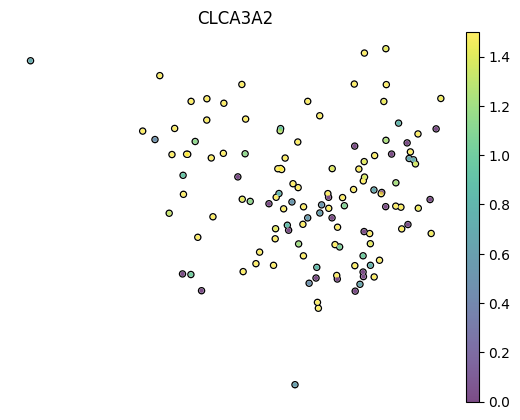

In [41]:
sc.pl.umap(adata[ adata.obs['Time'] == 'D30' ], color=['sub_cluster2'], frameon  = False, s = 20, add_outline = True, legend_loc = 'on data')  

sc.pl.umap(adata[ ( adata.obs['Time'] == 'D30' ) &
                 (adata.obs['Condition'] == 'Control') &
                (adata.obs['sub_cluster2'] == 'UB_2')],
           
           color=['CLCA3A2'], frameon  = False, s = 40, add_outline = True, legend_loc = 'on data',vmax = 1.5)  


sc.pl.umap(adata[ ( adata.obs['Time'] == 'D30' ) &
                 (adata.obs['Condition'] == 'PIMQ') &
                (adata.obs['sub_cluster2'] == 'UB_2') ], color=['CLCA3A2'], frameon  = False, s = 40, add_outline = True, legend_loc = 'on data', vmax = 1.5)  